# Milestone 1 — F1 Podium Prediction Companion

Predict per-driver podium (`positionOrder <= 3`) from pre-race info only (cutoff: after qualifying, before race start).

Background and rulings: `docs/` (decisions, leakage spec, method notes). Run top to bottom; figures regenerate.


## 1. Setup

Imports, seeds, paths (Kaggle vs local).


In [93]:
!pip install -q shap lime missingno
%matplotlib inline

# --- Lab 1: data wrangling & visualization ----------------------------------
import glob
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    import missingno as msno
except ImportError:  # kernel whose `!pip` targets another env: install into the kernel env
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "missingno"])
    import missingno as msno

# --- Labs 2-3: classical ML (imported once so versions print in one place) --
import sklearn

# --- Lab 3: neural networks (preinstalled on Kaggle; guarded for local runs) -
try:
    import tensorflow as tf
    from tensorflow import keras
    TF_OK = True
except Exception as _tf_err:
    tf = None
    TF_OK = False
    print(f"(tensorflow not available in this session: {_tf_err})")

# --- Lab 4: explainable AI (installed by the first line, exactly as Lab 4) --
import shap
import lime

# --- reproducibility: Lab 3 seed pattern ------------------------------------
SEED = 42
RANDOM_STATE = SEED
np.random.seed(SEED)
if TF_OK:
    tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 300)

# --- data path detection (Kaggle vs local) ----------------------------------
# On Kaggle the 14 raw CSVs are attached as a dataset under /kaggle/input.
# Locally we fall back to data/raw/. This is the ONLY environment difference.
kaggle_hits = glob.glob("/kaggle/input/**/results.csv", recursive=True)
if kaggle_hits:
    RAW_DIR = Path(kaggle_hits[0]).parent
    ON_KAGGLE = True
else:
    HERE = Path.cwd().resolve()       # nbconvert starts kernels in the notebook's folder
    ROOT = HERE.parent if HERE.name == "notebooks" else HERE
    RAW_DIR = ROOT / "data" / "raw"
    ON_KAGGLE = False

# --- figure output (regenerated every run, never an input) -------------------
WORKING = Path("/kaggle/working") if ON_KAGGLE else (ROOT / "notebooks" / "_working_local")
FIG_DIR = WORKING / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"ON_KAGGLE = {ON_KAGGLE}")
print(f"RAW_DIR   = {RAW_DIR} ({len(list(RAW_DIR.glob('*.csv')))} CSVs, read-only)")
print(f"FIG_DIR   = {FIG_DIR}")
print(f"SEED      = {SEED}")
import matplotlib
from importlib.metadata import version as _pkgv
print(f"pandas={pd.__version__} numpy={np.__version__} sklearn={sklearn.__version__} "
      f"matplotlib={matplotlib.__version__} seaborn={sns.__version__} missingno={msno.__version__}")
print(f"shap={shap.__version__} lime={_pkgv('lime')} "
      f"tensorflow={(tf.__version__ if TF_OK else 'not installed in this session')}")


(tensorflow not available in this session: No module named 'tensorflow')
ON_KAGGLE = False
RAW_DIR   = /home/nour/CSEN903/data/raw (14 CSVs, read-only)
FIG_DIR   = /home/nour/CSEN903/notebooks/_working_local/figures
SEED      = 42
pandas=3.0.6 numpy=2.5.3 sklearn=1.9.1 matplotlib=3.11.2 seaborn=0.13.2 missingno=0.5.2
shap=0.52.0 lime=0.2.0.1 tensorflow=not installed in this session


## 2. Load raw CSVs

14 tables into `data`, as stored (`\N` kept visible; cleaning happens on copies in §12).


In [94]:
TABLES = [
    "circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying",
    "lap_times", "pit_stops", "seasons", "sprint_results", "status",
]

csv_paths = {t: RAW_DIR / f"{t}.csv" for t in TABLES}
missing = [str(v) for v in csv_paths.values() if not v.exists()]
assert not missing, f"missing CSVs: {missing} (RAW_DIR={RAW_DIR})"

# dtype=str + keep_default_na=False: sentinels stay visible as the literal "\N".
data = {t: pd.read_csv(csv_paths[t], dtype=str, keep_default_na=False) for t in TABLES}

assert sorted(data) == sorted(TABLES), "expected all 14 tables"

# SHA-256 of every raw CSV (Gate 1.A evidence; re-asserted at the end of the notebook).
import hashlib
checksums = {}
for t in TABLES:
    h = hashlib.sha256()
    with open(csv_paths[t], "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    checksums[t] = h.hexdigest()
RAW_CHECKSUMS = pd.Series(checksums, name="sha256")
display(RAW_CHECKSUMS.to_frame())

inventory = pd.DataFrame({
    "rows":        {t: len(df) for t, df in data.items()},
    "cols":        {t: df.shape[1] for t, df in data.items()},
    "memory_MB":   {t: round(df.memory_usage(deep=True).sum() / 1e6, 2) for t, df in data.items()},
    "sentinels":   {t: int(df.map(lambda v: v == r"\N").sum().sum()) for t, df in data.items()},
})
inventory["sentinels_per_row"] = (inventory["sentinels"] / inventory["rows"]).round(2)
display(inventory.sort_values("rows", ascending=False))


,sha256
circuits,8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b021...
constructors,ae423f6f2d6cd74d5cd594eac0bdec7e1e9be2cda3097e...
constructor_results,8f1ebc0ce822bc02326b9bf13616f22a81514a6d35e5b7...
constructor_standings,9f07b1b9f235625165f62c6fcd6b1938cd7daa6f7e4a58...
drivers,6a894569cb031dd65fb5f113f57b235100966653eaedd9...
driver_standings,58397ed38d29f71316ba272a2ffd5bd00b6174774d919c...
races,4839d035abc603fa88fa08fa976a86d76cff35f3e94cb7...
results,a2392658044286800a0a946138067d9823f39e59147eee...
qualifying,49c4ff9ae0be93d5f850f56c553d5e264914c7ba0c4d58...
lap_times,70a772924f67682701acf1a6f26e8225ffd1b9f50844b2...


,rows,cols,memory_MB,sentinels,sentinels_per_row
lap_times,589081,6,41.19,0,0.00
driver_standings,34863,7,2.52,0,0.00
results,26759,18,4.99,122887,4.59
constructor_standings,13391,7,0.95,0,0.00
constructor_results,12625,5,0.66,12608,1.00
pit_stops,11371,7,0.96,0,0.00
qualifying,10494,9,1.09,11600,1.11
races,1125,18,0.30,11349,10.09
drivers,861,9,0.14,1559,1.81
sprint_results,360,16,0.06,73,0.20


### 2.1 Relational preview

`results` ⨝ `races` ⨝ `circuits` ⨝ `drivers` ⨝ `constructors` ⨝ `status` (2024 sample).


In [95]:
# Preview: results ⨝ races ⨝ circuits ⨝ drivers ⨝ constructors ⨝ status.
preview = (
    data["results"][["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]]
    .merge(data["races"][["raceId", "year", "round", "name", "circuitId"]], on="raceId")
    .merge(data["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId")
    .merge(data["drivers"][["driverId", "forename", "surname"]], on="driverId")
    .merge(data["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
    .merge(data["status"][["statusId", "status"]], on="statusId")
)
preview["driver"] = preview["forename"] + " " + preview["surname"]
preview = preview.rename(columns={"name": "race"})[["year", "round", "race", "circuit", "driver", "constructor", "grid", "positionOrder", "status"]]
preview["year"] = preview["year"].astype(int)
preview = preview[preview["year"] == 2024].sort_values(["round", "positionOrder"]).head(12)
display(preview.reset_index(drop=True))


,year,round,race,circuit,driver,constructor,grid,positionOrder,status
0,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Max Verstappen,Red Bull,1,1,Finished
1,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Lance Stroll,Aston Martin,12,10,Finished
2,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Guanyu Zhou,Sauber,17,11,+1 Lap
3,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Kevin Magnussen,Haas F1 Team,15,12,+1 Lap
4,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Daniel Ricciardo,RB F1 Team,14,13,+1 Lap
5,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Yuki Tsunoda,RB F1 Team,11,14,+1 Lap
6,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Alexander Albon,Williams,13,15,+1 Lap
7,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Nico Hülkenberg,Haas F1 Team,10,16,+1 Lap
8,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Esteban Ocon,Alpine F1 Team,19,17,+1 Lap
9,2024,1,Bahrain Grand Prix,Bahrain International Circuit,Pierre Gasly,Alpine F1 Team,20,18,+1 Lap


## 3. Raw profile

Lab 1 sequence: `shape`, `head`, `info`, `describe`, `isnull` + `(df == "\N")`, `value_counts`.


In [96]:
# Lab 1, step 1: shape of every table (how big is each piece?)
shapes = pd.DataFrame({
    "rows": {t: len(df) for t, df in data.items()},
    "cols": {t: df.shape[1] for t, df in data.items()},
})
display(shapes.sort_values("rows", ascending=False))


,rows,cols
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


In [97]:
# Lab 1, step 2: head() - what does one raw record look like?
for t in ["results", "races", "qualifying"]:
    print(f"--- {t}.head() ---")
    display(data[t].head(3))


--- results.head() ---


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6,58,+8.163,5698779,41,5,1:28.090,216.719,1


--- races.head() ---


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


--- qualifying.head() ---


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079


In [98]:
# Lab 1, step 3: info() - dtypes and non-null counts (raw: everything is str)
for t in ["results", "races", "qualifying"]:
    print(f"===== {t}.info() =====")
    data[t].info()


===== results.info() =====
<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   resultId         26759 non-null  str  
 1   raceId           26759 non-null  str  
 2   driverId         26759 non-null  str  
 3   constructorId    26759 non-null  str  
 4   number           26759 non-null  str  
 5   grid             26759 non-null  str  
 6   position         26759 non-null  str  
 7   positionText     26759 non-null  str  
 8   positionOrder    26759 non-null  str  
 9   points           26759 non-null  str  
 10  laps             26759 non-null  str  
 11  time             26759 non-null  str  
 12  milliseconds     26759 non-null  str  
 13  fastestLap       26759 non-null  str  
 14  rank             26759 non-null  str  
 15  fastestLapTime   26759 non-null  str  
 16  fastestLapSpeed  26759 non-null  str  
 17  statusId         26759 non-null  s

In [99]:
# Lab 1, step 4: describe() - on raw strings this gives count/unique/top/freq
for t in ["results", "races", "qualifying"]:
    print(f"===== {t}.describe(include='all').T =====")
    display(data[t].describe(include="all").T)


===== results.describe(include='all').T =====


,count,unique,top,freq
resultId,26759,26759,1,1
raceId,26759,1125,800,55
driverId,26759,861,4,404
constructorId,26759,211,6,2439
number,26759,130,4,1019
grid,26759,35,0,1638
position,26759,34,\N,10953
positionText,26759,39,R,8897
positionOrder,26759,39,3,1135
points,26759,39,0,18589


===== races.describe(include='all').T =====


,count,unique,top,freq
raceId,1125,1125,1,1
year,1125,75,2024,24
round,1125,24,1,75
circuitId,1125,77,14,74
name,1125,54,British Grand Prix,75
date,1125,1125,2009-03-29,1
time,1125,35,\N,731
url,1125,1125,http://en.wikipedia.org/wiki/2009_Australian_G...,1
fp1_date,1125,91,\N,1035
fp1_time,1125,21,\N,1057


===== qualifying.describe(include='all').T =====


,count,unique,top,freq
qualifyId,10494,10494,1,1
raceId,10494,494,259,28
driverId,10494,172,4,387
constructorId,10494,47,6,988
number,10494,58,11,478
position,10494,28,1,494
q1,10494,9147,\N,156
q2,10494,5475,\N,4625
q3,10494,3472,\N,6819


In [100]:
# Lab 1, step 5: isnull() sees (almost) nothing - the missingness hides in "\N"
for t in ["results", "qualifying", "races"]:
    df = data[t]
    check = pd.DataFrame({
        "isnull": df.isnull().sum(),
        "backslash_N": (df == r"\N").sum(),
        "empty": (df == "").sum(),
    })
    print(f"===== {t}: isnull vs sentinel =====")
    display(check[check.sum(axis=1) > 0].sort_values("backslash_N", ascending=False))


===== results: isnull vs sentinel =====


,isnull,backslash_N,empty
milliseconds,0,19079,0
time,0,19079,0
fastestLapTime,0,18507,0
fastestLap,0,18507,0
fastestLapSpeed,0,18507,0
rank,0,18249,0
position,0,10953,0
number,0,6,0


===== qualifying: isnull vs sentinel =====


,isnull,backslash_N,empty
q3,0,6819,46
q2,0,4625,22
q1,0,156,0


===== races: isnull vs sentinel =====


,isnull,backslash_N,empty
sprint_time,0,1110,0
sprint_date,0,1107,0
fp3_time,0,1072,0
quali_time,0,1057,0
fp2_time,0,1057,0
fp1_time,0,1057,0
fp3_date,0,1053,0
fp2_date,0,1035,0
fp1_date,0,1035,0
quali_date,0,1035,0


In [101]:
# Lab 1, step 6: value_counts() - the "Male/male/M" spelling check for F1
# NOTE: status counted over race entries, not the 139-row lookup.
print("status at race entries (top 10):")
display(data["results"].merge(data["status"], on="statusId")["status"].value_counts().head(10))
print("driver nationality (top 10 - demonyms like British, not countries):")
display(data["drivers"]["nationality"].value_counts().head(10))
print("circuit country (all - spot USA vs United States, UK aliases):")
display(data["circuits"]["country"].value_counts())


status at race entries (top 10):


status
Finished           7674
+1 Lap             4037
Engine             2026
+2 Laps            1613
Accident           1062
Did not qualify    1025
Collision           854
Gearbox             810
Spun off            795
+3 Laps             731
Name: count, dtype: int64

driver nationality (top 10 - demonyms like British, not countries):


nationality
British          166
American         158
Italian           99
French            73
German            50
Brazilian         32
Argentine         24
Swiss             23
Belgian           23
South African     23
Name: count, dtype: int64

circuit country (all - spot USA vs United States, UK aliases):


country
USA              11
France            7
Spain             6
UK                4
Italy             4
Portugal          4
Canada            3
Germany           3
Belgium           3
Japan             3
Australia         2
Brazil            2
South Africa      2
Austria           2
Malaysia          1
Bahrain           1
Turkey            1
Monaco            1
Hungary           1
Singapore         1
China             1
United States     1
UAE               1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

## 4. Sentinel audit

`\N` census per table/column (before picture; rules: `docs/method-notes.md`).


In [102]:
rows = []
for t, df in data.items():
    for c in df.columns:
        n = int(df[c].astype(str).eq(r"\N").sum())
        if n:
            rows.append({"table": t, "column": c, "sentinels": n, "share": n / len(df)})

sentinels = (pd.DataFrame(rows)
             .sort_values("sentinels", ascending=False)
             .reset_index(drop=True))
display(sentinels.assign(share=sentinels["share"].map("{:.1%}".format)).head(25).reset_index(drop=True))
print(f"total sentinel cells across all tables: {sentinels['sentinels'].sum():,}")

,table,column,sentinels,share
0,results,time,19079,71.3%
1,results,milliseconds,19079,71.3%
2,results,fastestLap,18507,69.2%
3,results,fastestLapTime,18507,69.2%
4,results,fastestLapSpeed,18507,69.2%
5,results,rank,18249,68.2%
6,constructor_results,status,12608,99.9%
7,results,position,10953,40.9%
8,qualifying,q3,6819,65.0%
9,qualifying,q2,4625,44.1%


total sentinel cells across all tables: 160,076


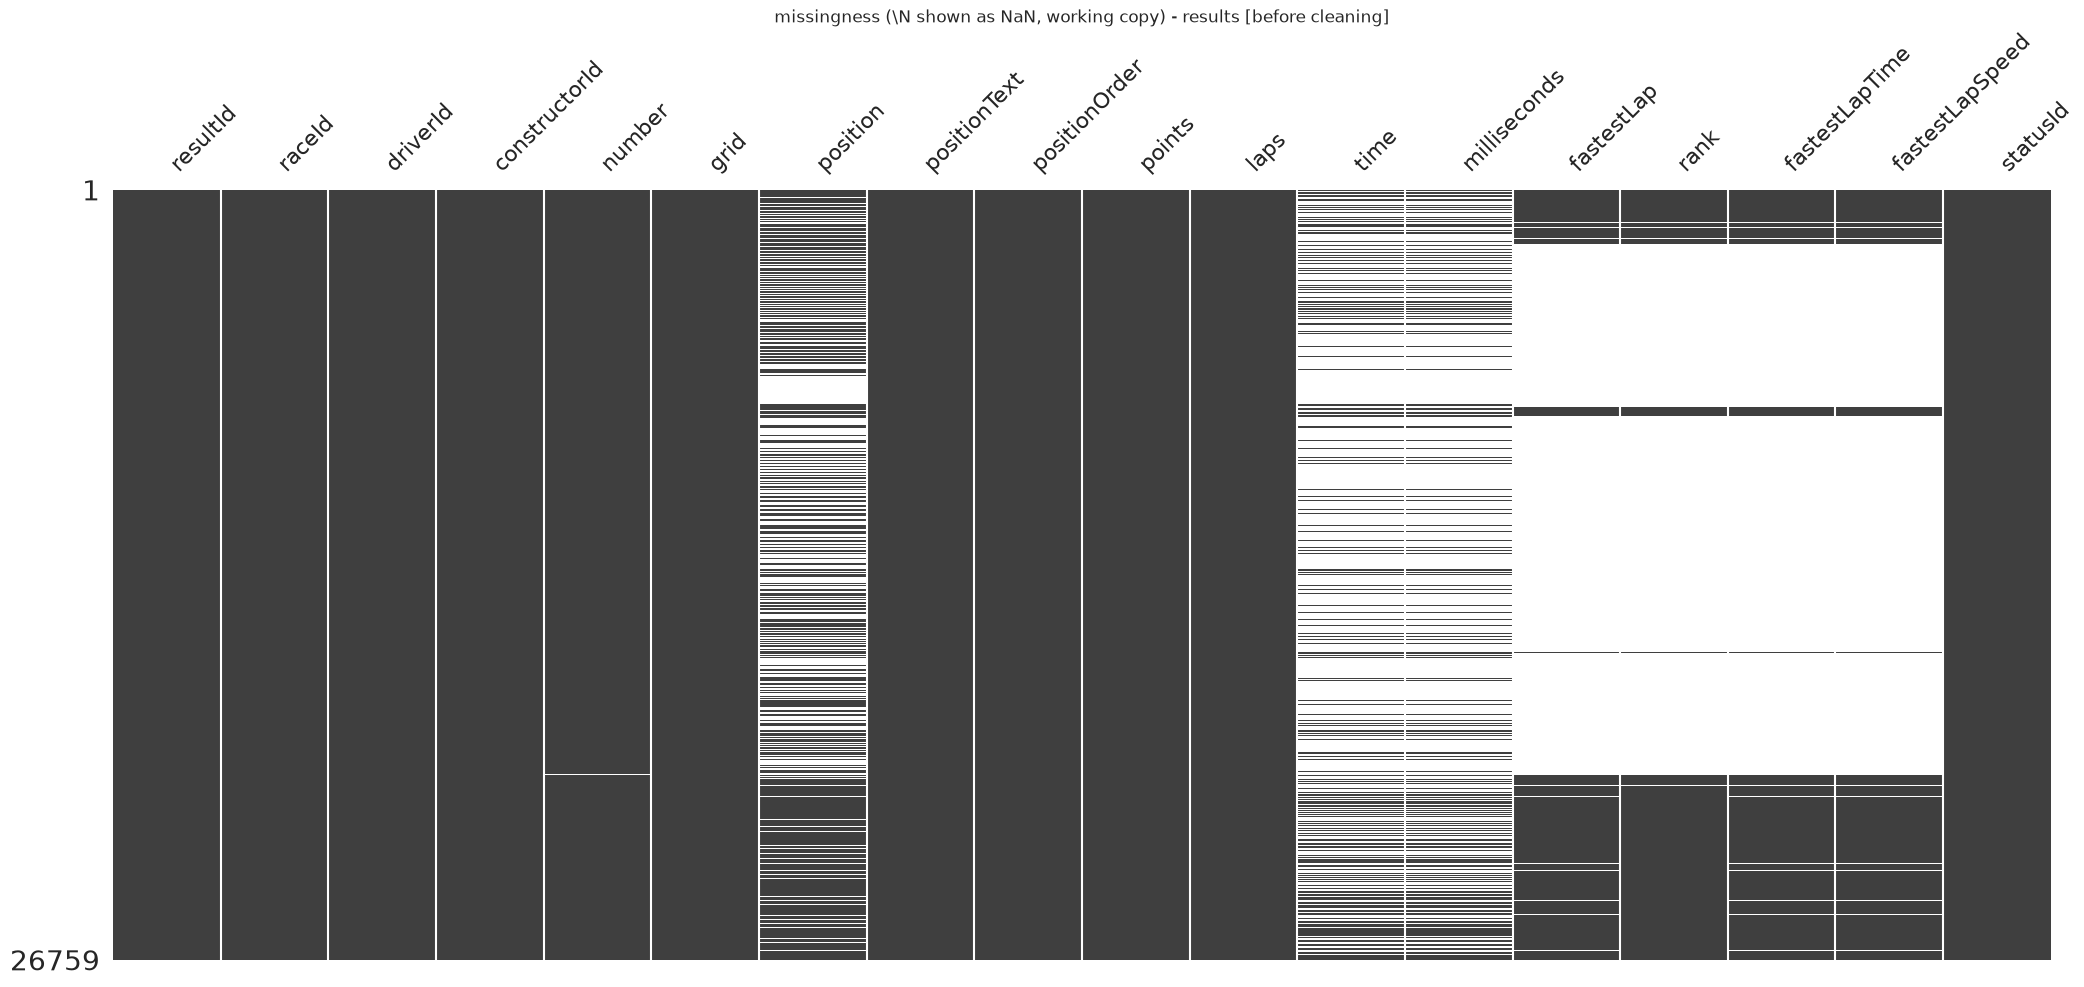

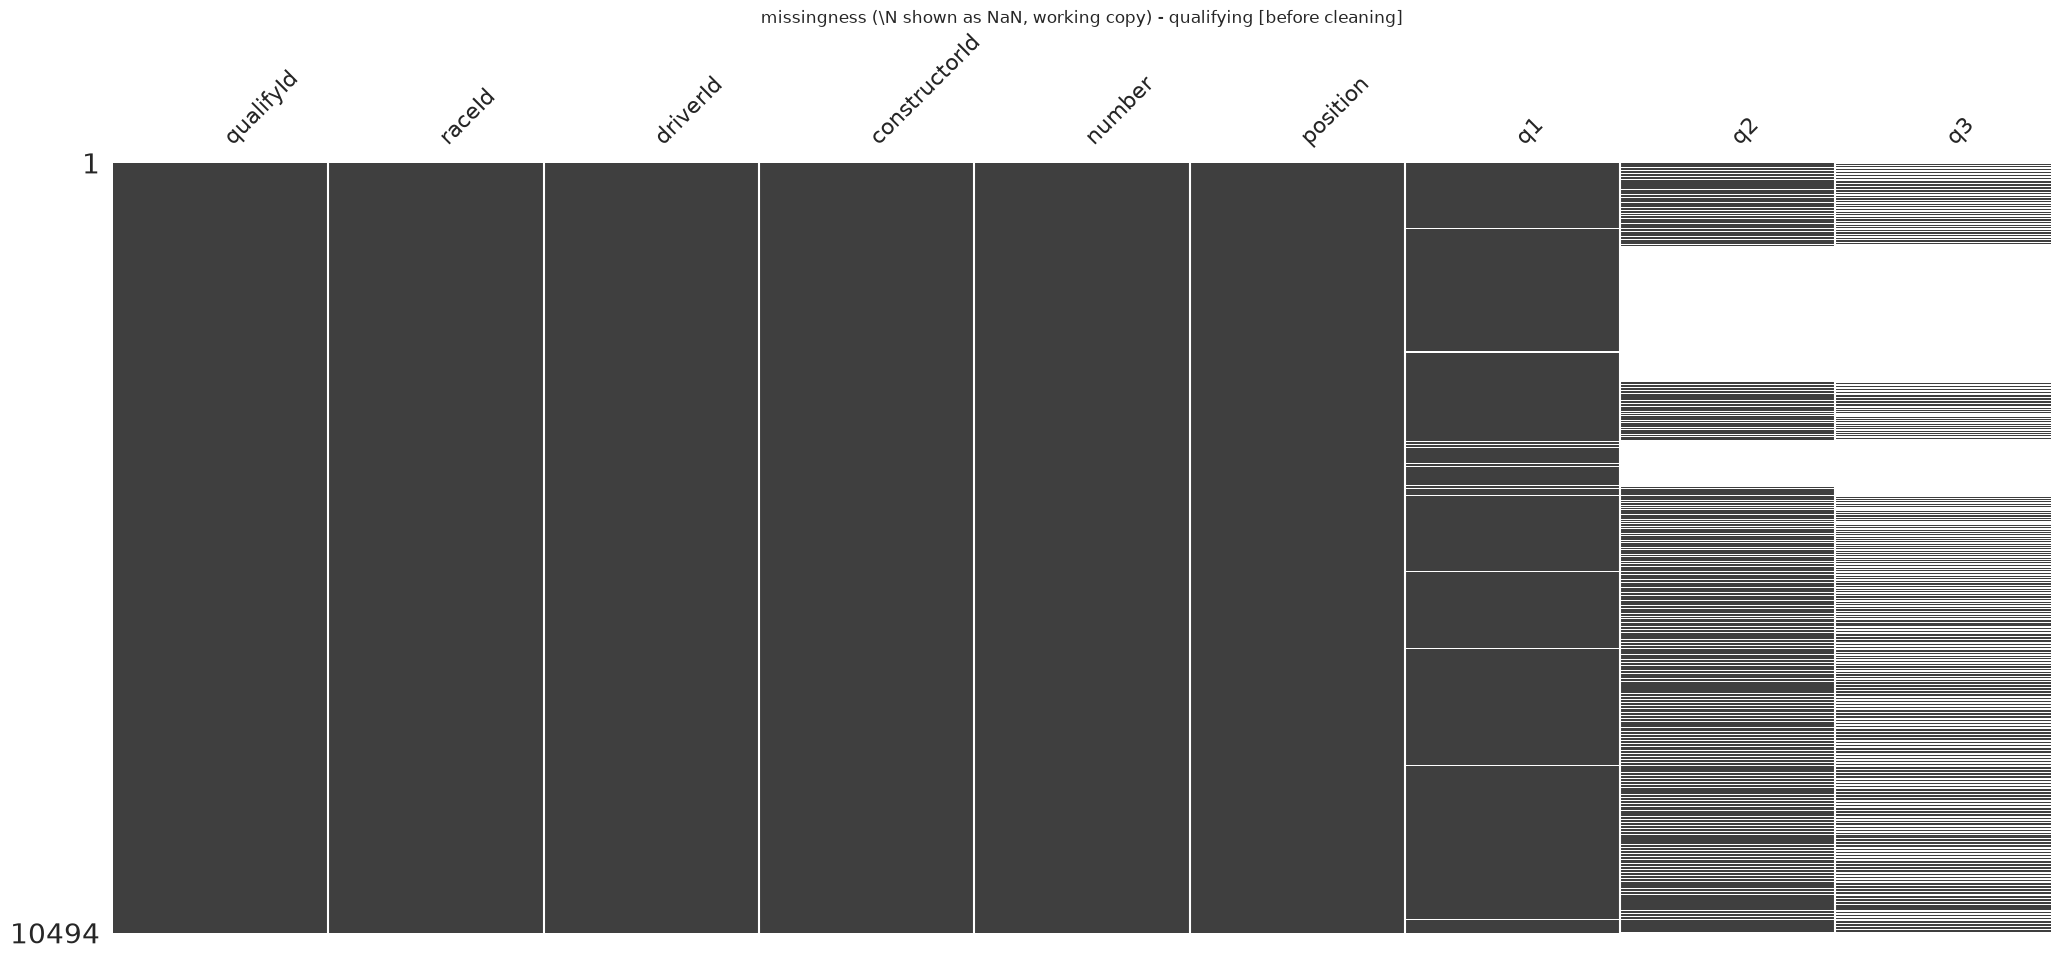

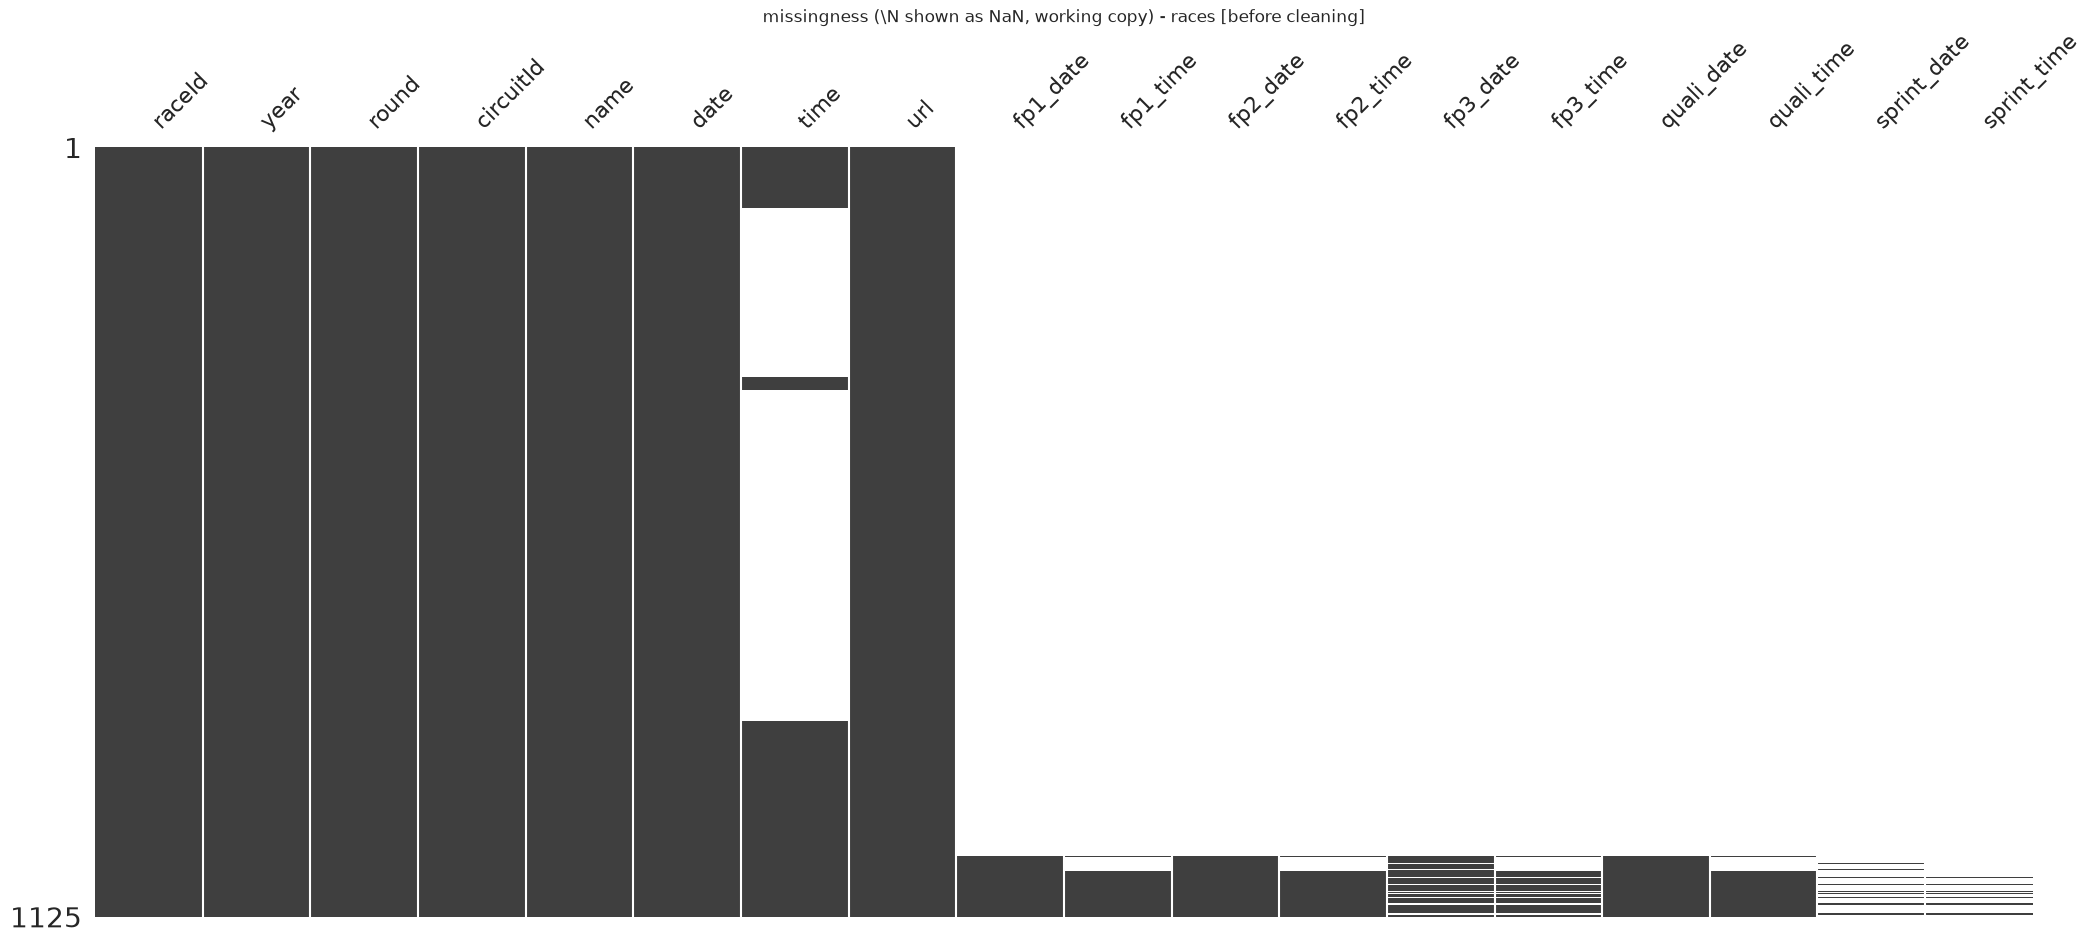

In [103]:
# Lab 1 missingness pattern: map \N -> NaN on a COPY, then msno.matrix (before picture)
for t in ["results", "qualifying", "races"]:
    tmp = data[t].replace(r"\N", np.nan)
    msno.matrix(tmp, sparkline=False)
    plt.title(f"missingness (\\N shown as NaN, working copy) - {t} [before cleaning]")
    plt.savefig(FIG_DIR / f"fig_01_msno_{t}.png", dpi=150, bbox_inches="tight")
    plt.show()


### Gate 1.A: version check

Expect 14 tables, 1950–2024; pin to `year <= 2024` if the Kaggle copy differs.


In [104]:
races_y = data["races"]["year"].astype(int)
print(f"seasons: {races_y.min()}-{races_y.max()} ({data['seasons'].shape[0]} rows in seasons.csv)")
print(f"races  : {len(data['races']):,}  | results rows: {len(data['results']):,}")
print(f"tables : {len(data)} (expected 14)")
yr_max = int(races_y.max())
if yr_max > 2024:
    print(f"NOTE: dataset extends to {yr_max} > 2024 -> analysis will pin to year <= 2024 (Gate 1.A rule).")
else:
    print("Gate 1.A: version matches the plan (1950-2024). Proceed.")
display(data["races"].assign(year=races_y).groupby("year").size().rename("races").tail(8).to_frame().T)


seasons: 1950-2024 (75 rows in seasons.csv)
races  : 1,125  | results rows: 26,759
tables : 14 (expected 14)
Gate 1.A: version matches the plan (1950-2024). Proceed.


year,2017,2018,2019,2020,2021,2022,2023,2024
races,20,21,21,17,22,22,22,24


### Gate 1.B: sentinel registry

Scan `''`, `NA`, `-1`, zero sentinels (rules: `docs/method-notes.md`).


In [105]:
extra = []
for t, df in data.items():
    for c in df.columns:
        s = df[c].astype(str)
        n_empty = int((df[c] == "").sum())
        n_na = int(s.eq("NA").sum())
        n_neg1 = int(s.eq("-1").sum())
        if n_empty: extra.append((t, c, '""', n_empty))
        if n_na: extra.append((t, c, '"NA"', n_na))
        if n_neg1: extra.append((t, c, '"-1"', n_neg1))
extra_rep = pd.DataFrame(extra, columns=["table", "column", "sentinel", "n"]) if extra else pd.DataFrame(columns=["table","column","sentinel","n"])
print("non-\\N placeholders found:")
display(extra_rep.sort_values("n", ascending=False).head(20) if len(extra_rep) else extra_rep)

# Zero sentinels (Gate 2.D):
r = data["results"]
print(f"results.grid == '0'      : {(r['grid'] == '0').sum():,} rows (pit-lane starts vs DNQ -> Gate 2.D)")
print(f"results.position == '0'  : {(r['position'] == '0').sum():,} rows")
print(f"results.number == ''     : {(r['number'] == '').sum():,} rows")
cir = data["circuits"]
print(f"circuits lat==0 & lng==0 : {((cir['lat'] == '0') & (cir['lng'] == '0')).sum()} rows")
q = data["qualifying"]
for c in ["q1", "q2", "q3"]:
    print(f"qualifying.{c} == ''   : {(q[c] == '').sum():,} rows")
print("Gate 1.B registry set (rules: docs/method-notes.md).")


non-\N placeholders found:


,table,column,sentinel,n
1,qualifying,q3,"""""",46
0,qualifying,q2,"""""",22


results.grid == '0'      : 1,638 rows (pit-lane starts vs DNQ -> Gate 2.D)
results.position == '0'  : 0 rows
results.number == ''     : 0 rows
circuits lat==0 & lng==0 : 0 rows
qualifying.q1 == ''   : 0 rows
qualifying.q2 == ''   : 22 rows
qualifying.q3 == ''   : 46 rows
Gate 1.B: registry = {\N: standard NaN} + {grid=0, position=0, lat/lng=0, '': per-column rules in Phase 2}.


### Before-cleaning plots

`missingno` per table; `\N`-rate heatmap; races/entries; numeric distributions.


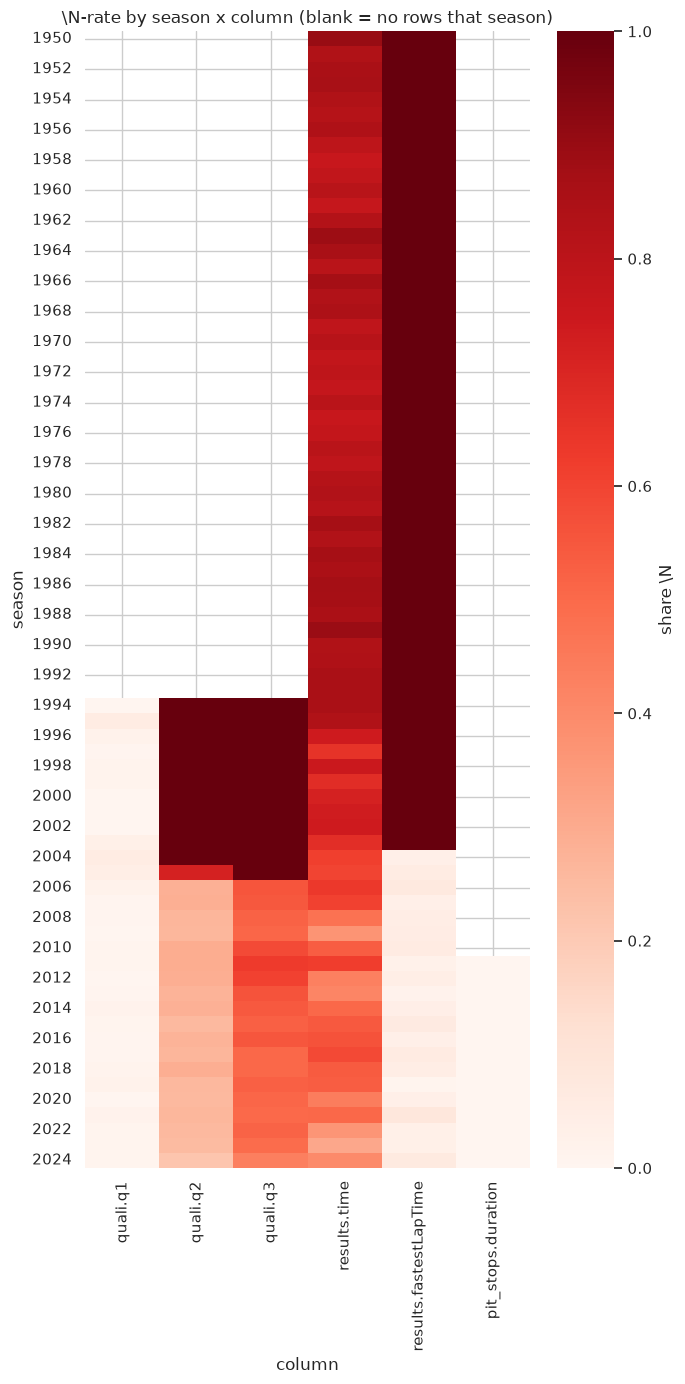

metric,quali.q1,quali.q2,quali.q3,results.time,results.fastestLapTime,pit_stops.duration
year,,,,,,
1994,0.003,1.000,1.000,0.858,1.000,NaN
2001,0.000,1.000,1.000,0.735,1.000,NaN
2003,0.034,1.000,1.000,0.669,1.000,NaN
2014,0.017,0.281,0.546,0.506,0.039,0.0
2024,0.008,0.217,0.434,0.399,0.067,0.0


In [106]:
# Lab 1 relationship-over-time: \N-rate by season x column (pivot_table + heatmap)
ry = data["races"][["raceId", "year"]].copy()
ry["year"] = ry["year"].astype(int)
q = data["qualifying"].merge(ry, on="raceId")
r = data["results"].merge(ry, on="raceId")
ps = data["pit_stops"].merge(ry, on="raceId")

parts = []
for col, label in [("q1", "quali.q1"), ("q2", "quali.q2"), ("q3", "quali.q3")]:
    parts.append(pd.DataFrame({"year": q["year"], "metric": label, "missing": q[col].eq(r"\N").astype(int)}))
for col, label in [("time", "results.time"), ("fastestLapTime", "results.fastestLapTime")]:
    parts.append(pd.DataFrame({"year": r["year"], "metric": label, "missing": r[col].eq(r"\N").astype(int)}))
parts.append(pd.DataFrame({"year": ps["year"], "metric": "pit_stops.duration",
                            "missing": ps["duration"].eq(r"\N").astype(int)}))
long = pd.concat(parts, ignore_index=True)
nrate = pd.pivot_table(long, index="year", columns="metric", values="missing", aggfunc="mean")
nrate = nrate[["quali.q1", "quali.q2", "quali.q3", "results.time", "results.fastestLapTime", "pit_stops.duration"]]

fig, ax = plt.subplots(figsize=(7, 14))
sns.heatmap(nrate, cmap="Reds", cbar_kws={"label": "share \\N"}, ax=ax)
ax.set_title("\\N-rate by season x column (blank = no rows that season)")
ax.set_xlabel("column")
ax.set_ylabel("season")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_02_nrate_heatmap.png", dpi=150)
plt.show()
display(nrate.loc[[1994, 2001, 2003, 2014, 2024]].round(3))


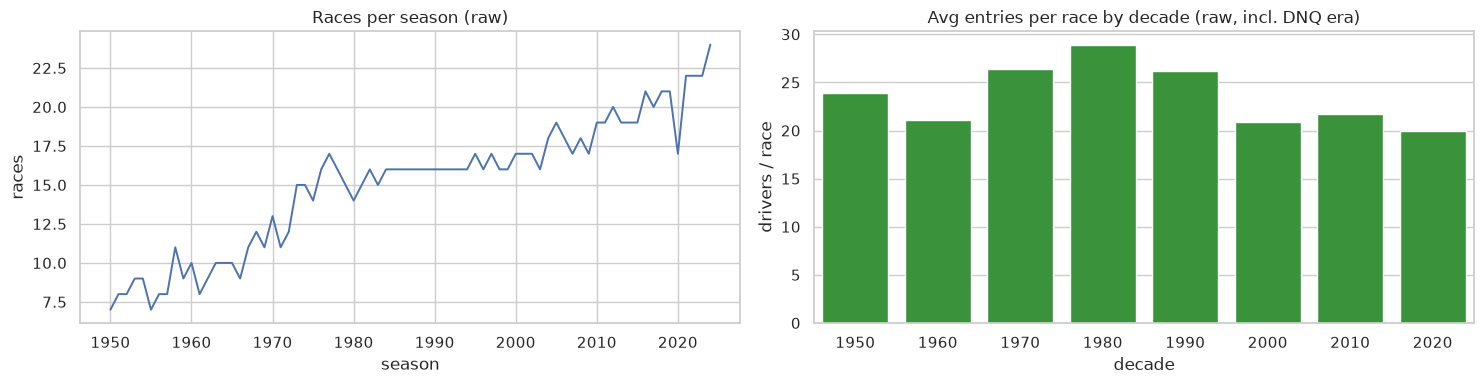

seasons 1950-2024, total races 1,125, avg entries/race 23.8


In [107]:
# Lab 1 comparison: races per season (line) + avg entries per race by decade (barplot)
ry = data["races"][["raceId", "year"]].copy()
ry["year"] = ry["year"].astype(int)
n_races = ry.groupby("year").size()
entries = data["results"].merge(ry, on="raceId")
entries["decade"] = (entries["year"] // 10) * 10
dec_races = ry.groupby((ry["year"] // 10) * 10).size().rename("races")
dec_entries = entries.groupby("decade").size() / dec_races

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(n_races.index, n_races.values, lw=1.4)
axes[0].set_title("Races per season (raw)")
axes[0].set_xlabel("season")
axes[0].set_ylabel("races")
sns.barplot(x=dec_entries.index.astype(str), y=dec_entries.values, ax=axes[1], color="#2ca02c")
axes[1].set_title("Avg entries per race by decade (raw, incl. DNQ era)")
axes[1].set_xlabel("decade")
axes[1].set_ylabel("drivers / race")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_03_seasons.png", dpi=150)
plt.show()
print(f"seasons {int(n_races.index.min())}-{int(n_races.index.max())}, "
      f"total races {len(ry):,}, avg entries/race {len(entries) / len(ry):.1f}")


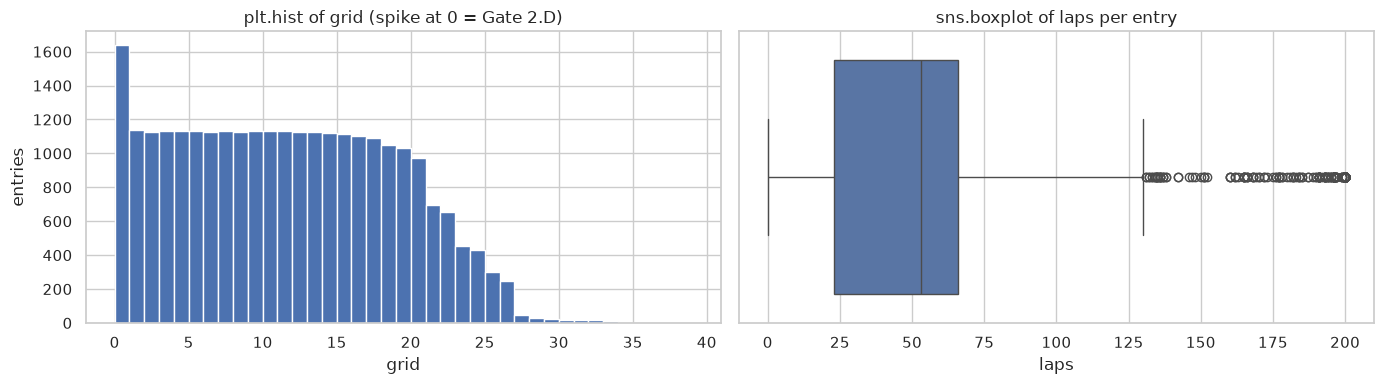

,grid,laps,points,positionOrder
count,26759.00,26759.0,26759.00,26759.00
mean,11.13,46.3,1.99,12.79
std,7.20,29.5,4.35,7.67
min,0.00,0.0,0.00,1.00
25%,5.00,23.0,0.00,6.00
50%,11.00,53.0,0.00,12.00
75%,17.00,66.0,2.00,18.00
max,34.00,200.0,50.00,39.00


In [108]:
# Lab 1 distribution: numerics on copies (\N -> NaN -> numeric) to spot outliers
res_num = pd.DataFrame({
    "grid": pd.to_numeric(data["results"]["grid"].replace(r"\N", np.nan), errors="coerce"),
    "laps": pd.to_numeric(data["results"]["laps"].replace(r"\N", np.nan), errors="coerce"),
    "points": pd.to_numeric(data["results"]["points"].replace(r"\N", np.nan), errors="coerce"),
    "positionOrder": pd.to_numeric(data["results"]["positionOrder"].replace(r"\N", np.nan), errors="coerce"),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(res_num["grid"].dropna(), bins=range(0, 40))
axes[0].set_title("plt.hist of grid (spike at 0 = Gate 2.D)")
axes[0].set_xlabel("grid")
axes[0].set_ylabel("entries")
sns.boxplot(x=res_num["laps"], ax=axes[1])
axes[1].set_title("sns.boxplot of laps per entry")
axes[1].set_xlabel("laps")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_04_numeric_dist.png", dpi=150)
plt.show()
display(res_num.describe().round(2))


Reading: `position` gaps = retirements (never impute); q2/q3 gaps = era coverage; `grid = 0` → Gate 2.D. Full notes: `docs/method-notes.md`.


## 5. PK/FK checks

PKs unique, non-null, sentinel-free; 0 FK orphans (fail loudly).


In [109]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"], "driver_standings": ["driverStandingsId"],
    "races": ["raceId"], "results": ["resultId"], "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}

pk_report = []
for t, cols in PRIMARY_KEYS.items():
    df = data[t]
    pk_report.append({
        "table": t,
        "pk": " + ".join(cols),
        "rows": len(df),
        "unique": df.drop_duplicates(cols).shape[0] == len(df),
        "nulls": int(df[cols].isna().sum().sum()),
        "sentinels": int(df[cols].astype(str).eq(r"\N").sum().sum()),
    })
pk_report = pd.DataFrame(pk_report)
display(pk_report)

assert pk_report["unique"].all(),  "duplicate primary keys found"
assert pk_report["nulls"].eq(0).all(),   "null primary keys found"
assert pk_report["sentinels"].eq(0).all(), "sentinel in primary key found"
print("all 14 primary keys unique, non-null and sentinel-free")

,table,pk,rows,unique,nulls,sentinels
0,circuits,circuitId,77,True,0,0
1,constructors,constructorId,212,True,0,0
2,constructor_results,constructorResultsId,12625,True,0,0
3,constructor_standings,constructorStandingsId,13391,True,0,0
4,drivers,driverId,861,True,0,0
5,driver_standings,driverStandingsId,34863,True,0,0
6,races,raceId,1125,True,0,0
7,results,resultId,26759,True,0,0
8,qualifying,qualifyId,10494,True,0,0
9,lap_times,raceId + driverId + lap,589081,True,0,0


all 14 primary keys unique, non-null and sentinel-free


In [110]:
FOREIGN_KEYS = {
    "constructor_results": [("raceId", "races", "raceId"), ("constructorId", "constructors", "constructorId")],
    "constructor_standings": [("raceId", "races", "raceId"), ("constructorId", "constructors", "constructorId")],
    "driver_standings": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId")],
    "races": [("circuitId", "circuits", "circuitId")],
    "results": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId"),
                ("constructorId", "constructors", "constructorId"), ("statusId", "status", "statusId")],
    "qualifying": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId"),
                   ("constructorId", "constructors", "constructorId")],
    "lap_times": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId")],
    "pit_stops": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId")],
    "sprint_results": [("raceId", "races", "raceId"), ("driverId", "drivers", "driverId"),
                       ("constructorId", "constructors", "constructorId"), ("statusId", "status", "statusId")],
}

fk_report = []
for t, fks in FOREIGN_KEYS.items():
    for col, ref_t, ref_c in fks:
        orphans = int((~data[t][col].isin(data[ref_t][ref_c])).sum())
        fk_report.append({"table": t, "fk": col, "references": f"{ref_t}.{ref_c}",
                          "rows": len(data[t]), "orphans": orphans})
fk_report = pd.DataFrame(fk_report)
display(fk_report)

assert fk_report["orphans"].eq(0).all(), "foreign key violations found"
print(f"all {len(fk_report)} foreign keys reconcile - 0 orphans")

,table,fk,references,rows,orphans
0,constructor_results,raceId,races.raceId,12625,0
1,constructor_results,constructorId,constructors.constructorId,12625,0
2,constructor_standings,raceId,races.raceId,13391,0
3,constructor_standings,constructorId,constructors.constructorId,13391,0
4,driver_standings,raceId,races.raceId,34863,0
5,driver_standings,driverId,drivers.driverId,34863,0
6,races,circuitId,circuits.circuitId,1125,0
7,results,raceId,races.raceId,26759,0
8,results,driverId,drivers.driverId,26759,0
9,results,constructorId,constructors.constructorId,26759,0


all 22 foreign keys reconcile - 0 orphans


## 6. Grain

One row per `(raceId, driverId)`; shared-drive duplicates (rule D3: `docs/decisions.md`).


In [111]:
res = data["results"]
KEY = ["raceId", "driverId"]

dup_mask = res.duplicated(KEY, keep=False)
dups = res[dup_mask].sort_values(KEY)
n_pairs = dups.groupby(KEY).ngroups
n_unique = res.drop_duplicates(KEY).shape[0]

print(f"results rows              : {len(res):,}")
print(f"unique (raceId, driverId) : {n_unique:,}")
print(f"duplicated pairs           : {n_pairs}   (rows involved: {int(dup_mask.sum())})")
print(f"rows to remove for grain   : {len(res) - n_unique}")

# do the duplicate rows disagree about the outcome?
disagree = dups.groupby(KEY)["positionOrder"].nunique().gt(1).sum()
print(f"pairs with conflicting positionOrder: {disagree} of {n_pairs}")

ctx = (dups.merge(data["races"][["raceId", "year", "name"]], on="raceId")
           .merge(data["drivers"][["driverId", "forename", "surname"]], on="driverId"))
show = ["year", "name", "forename", "surname", "grid", "laps", "position", "positionOrder", "points"]
display(ctx[show].head(12))

print("\nduplicated pairs per season:")
display(ctx.drop_duplicates(KEY).groupby("year").size().rename("pairs").to_frame().T)

results rows              : 26,759
unique (raceId, driverId) : 26,668
duplicated pairs           : 85   (rows involved: 176)
rows to remove for grain   : 91
pairs with conflicting positionOrder: 85 of 85


,year,name,forename,surname,grid,laps,position,positionOrder,points
0,1978,Italian Grand Prix,Harald,Ertl,0,0,\N,26,0
1,1978,Italian Grand Prix,Harald,Ertl,0,0,\N,29,0
2,1964,United States Grand Prix,Jim,Clark,1,102,7,7,0
3,1964,United States Grand Prix,Jim,Clark,1,54,\N,12,0
4,1962,British Grand Prix,Keith,Greene,0,0,\N,22,0
5,1962,British Grand Prix,Keith,Greene,0,0,\N,25,0
6,1961,British Grand Prix,Stirling,Moss,20,56,\N,19,0
7,1961,British Grand Prix,Stirling,Moss,5,44,\N,21,0
8,1961,United States Grand Prix,Masten,Gregory,11,23,\N,17,0
9,1961,United States Grand Prix,Masten,Gregory,15,92,11,11,0



duplicated pairs per season:


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1960,1961,1962,1964,1978
pairs,4,4,3,14,16,15,12,8,3,1,2,1,1,1


**Dedup: R2** — keep the car the driver started in (lowest non-zero `grid`, tie-break first `resultId`). R1 above counted the gap only. Rationale: `docs/decisions.md`.


In [112]:
DEDUPE_RULE = "best_positionOrder_then_laps"


def dedupe_results(df: pd.DataFrame) -> pd.DataFrame:
    '''R1 dedupe (audit only; R2 applied in §12).'''
    tmp = df.copy()
    tmp["_pos"] = pd.to_numeric(tmp["positionOrder"].replace(r"\N", np.nan), errors="coerce")
    tmp["_laps"] = pd.to_numeric(tmp["laps"].replace(r"\N", np.nan), errors="coerce")
    ordered = tmp.sort_values(["_pos", "_laps"], ascending=[True, False], na_position="last").drop(columns=["_pos", "_laps"])
    out = ordered.drop_duplicates(KEY, keep="first")
    return out.sort_index()


modeling_grain = dedupe_results(res)
dropped = len(res) - len(modeling_grain)
assert not modeling_grain.duplicated(KEY).any()
assert len(modeling_grain) == n_unique
print(f"rule '{DEDUPE_RULE}': dropped {dropped} rows, grain now unique "
      f"({len(modeling_grain):,} rows)")

# show the record that survived for each duplicated driver-race
kept_for_dupes = modeling_grain.index.isin(dups.index)
kept_ctx = (modeling_grain.loc[kept_for_dupes]
            .merge(data["races"][["raceId", "year", "name"]], on="raceId")
            .merge(data["drivers"][["driverId", "forename", "surname"]], on="driverId"))
display(kept_ctx.sort_values(["year", "raceId", "positionOrder"])[show].head(8))

rule 'best_positionOrder_then_laps': dropped 91 rows, grain now unique (26,668 rows)


,year,name,forename,surname,grid,laps,position,positionOrder,points
17,1950,Indianapolis 500,Tony,Bettenhausen,9,136,5,5,1
18,1950,French Grand Prix,Louis,Rosier,15,56,6,6,0
20,1950,Italian Grand Prix,Juan,Fangio,7,34,\N,13,0
19,1950,Italian Grand Prix,Alberto,Ascari,6,80,2,2,3
15,1951,French Grand Prix,Luigi,Fagioli,7,77,1,1,4
21,1951,French Grand Prix,Juan,Fangio,7,77,1,1,5
16,1951,French Grand Prix,Alberto,Ascari,6,77,2,2,3
22,1951,Italian Grand Prix,Nino,Farina,7,79,3,3,3


## 7. Typing inventory

Sample date/time/duration formats; define the converters used in §12.


In [113]:
def sample_values(table, column, n=3):
    s = data[table][column]
    vals = [v for v in pd.unique(s)
            if not (isinstance(v, str) and v == r"\N") and pd.notna(v)]
    return list(vals[:n])


format_samples = pd.DataFrame([
    ("races.date", "calendar date", sample_values("races", "date")),
    ("races.time", "clock time (UTC)", sample_values("races", "time")),
    ("races.quali_date", "calendar date", sample_values("races", "quali_date")),
    ("drivers.dob", "calendar date", sample_values("drivers", "dob")),
    ("qualifying.q1", "lap time m:s.ms", sample_values("qualifying", "q1")),
    ("lap_times.time", "lap time m:s.ms", sample_values("lap_times", "time")),
    ("results.time", "race time h:m:s.ms", sample_values("results", "time")),
    ("results.fastestLapTime", "lap time m:s.ms", sample_values("results", "fastestLapTime")),
    ("pit_stops.duration", "duration seconds", sample_values("pit_stops", "duration")),
    ("pit_stops.time", "clock time (UTC)", sample_values("pit_stops", "time")),
], columns=["column", "semantic type", "raw examples"])
display(format_samples)

,column,semantic type,raw examples
0,races.date,calendar date,"[2009-03-29, 2009-04-05, 2009-04-19]"
1,races.time,clock time (UTC),"[06:00:00, 09:00:00, 07:00:00]"
2,races.quali_date,calendar date,"[2021-04-17, 2022-03-19, 2021-03-27]"
3,drivers.dob,calendar date,"[1985-01-07, 1977-05-10, 1985-06-27]"
4,qualifying.q1,lap time m:s.ms,"[1:26.572, 1:26.103, 1:25.664]"
5,lap_times.time,lap time m:s.ms,"[1:38.109, 1:33.006, 1:32.713]"
6,results.time,race time h:m:s.ms,"[1:34:50.616, +5.478, +8.163]"
7,results.fastestLapTime,lap time m:s.ms,"[1:27.452, 1:27.739, 1:28.090]"
8,pit_stops.duration,duration seconds,"[26.898, 25.021, 23.426]"
9,pit_stops.time,clock time (UTC),"[17:05:23, 17:05:52, 17:20:48]"


In [114]:
def time_to_seconds(v):
    '''22.450 | 1:27.274 | 34:50.711 | 1:34:50.711 -> float seconds; \\N/NaN -> NaN.'''
    if v is None or pd.isna(v):
        return np.nan
    if isinstance(v, str):
        v = v.strip()
        if v in (r"\N", ""):
            return np.nan
    try:
        secs = 0.0
        for part in str(v).split(":"):
            secs = secs * 60 + float(part)
        return secs
    except ValueError:
        return np.nan


demo = data["lap_times"].head(5)[["raceId", "driverId", "lap", "time"]].copy()
demo["seconds"] = demo["time"].map(time_to_seconds)
display(demo)

lt_ok = data["lap_times"]["time"].map(time_to_seconds)
rt = data["results"]["time"]
rt_non_sentinel = ~rt.isin([r"\N"])
print(f"lap_times.time  : {int(lt_ok.isna().sum())} parse failures / {len(lt_ok):,} rows")
print(f"results.time    : {int(rt[rt_non_sentinel].map(time_to_seconds).isna().sum())} parse failures "
      f"/ {int(rt_non_sentinel.sum()):,} non-sentinel rows")

parsed_dates = pd.to_datetime(data["races"]["date"], errors="coerce")
print(f"races.date      : {int(parsed_dates.isna().sum())} parse failures / {len(parsed_dates)} rows")
display(pd.DataFrame({"raw": data["races"]["date"].head(3),
                      "typed": parsed_dates.head(3).dt.date.values}))

,raceId,driverId,lap,time,seconds
0,841,20,1,1:38.109,98.109
1,841,20,2,1:33.006,93.006
2,841,20,3,1:32.713,92.713
3,841,20,4,1:32.803,92.803
4,841,20,5,1:32.342,92.342


lap_times.time  : 0 parse failures / 589,081 rows
results.time    : 0 parse failures / 7,680 non-sentinel rows
races.date      : 0 parse failures / 1125 rows


,raw,typed
0,2009-03-29,2009-03-29
1,2009-04-05,2009-04-05
2,2009-04-19,2009-04-19


## 8. Coverage EDA

Which fields exist in which era (qualifying drift → 2003+ window).


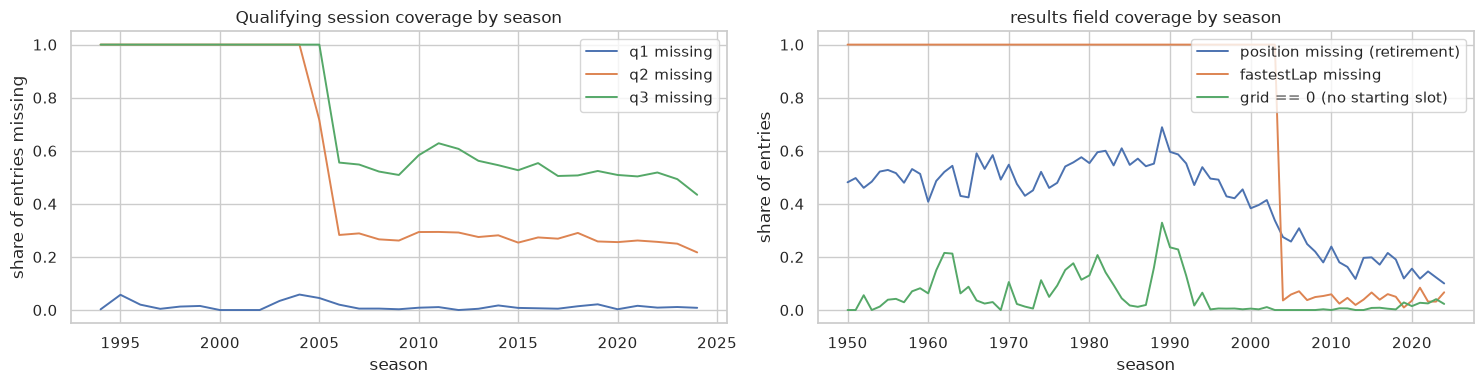

,q1 missing,q2 missing,q3 missing
era,,,
pre-2003,0.021,1.000,1.000
2003-2013,0.017,0.433,0.673
2014+,0.011,0.260,0.510


In [115]:
q = data["qualifying"].merge(data["races"][["raceId", "year"]], on="raceId")
q_cov = pd.DataFrame({
    "q1 missing": q["q1"].eq(r"\N"),
    "q2 missing": q["q2"].eq(r"\N"),
    "q3 missing": q["q3"].eq(r"\N"),
})
q_cov["year"] = q["year"].astype(int).values
by_year = q_cov.groupby("year").mean()

r = data["results"].merge(data["races"][["raceId", "year"]], on="raceId")
r_cov = pd.DataFrame({
    "position missing (retirement)": r["position"].eq(r"\N"),
    "fastestLap missing": r["fastestLap"].eq(r"\N"),
    "grid == 0 (no starting slot)": r["grid"].eq("0"),
})
r_cov["year"] = r["year"].astype(int).values
r_by_year = r_cov.groupby("year").mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
by_year.plot(ax=axes[0], lw=1.4)
axes[0].set_title("Qualifying session coverage by season")
axes[0].set_ylabel("share of entries missing")
axes[0].set_xlabel("season")

r_by_year.plot(ax=axes[1], lw=1.4)
axes[1].set_title("results field coverage by season")
axes[1].set_ylabel("share of entries")
axes[1].set_xlabel("season")
plt.tight_layout()
plt.show()

q_cov["era"] = pd.cut(q["year"].astype(int), [1949, 2002, 2013, 2025],
                      labels=["pre-2003", "2003-2013", "2014+"])
display(q_cov.groupby("era", observed=True)[["q1 missing", "q2 missing", "q3 missing"]]
        .mean().round(3))

Findings feed the window and Gate 2.D (details: `docs/method-notes.md`).


## 9. Target

`podium = positionOrder <= 3`; base rate by decade/season.


rows (unique driver-races): 26,668
podium finishes            : 3,395  (12.7%)
non-podium                 : 23,273  (87.3%)


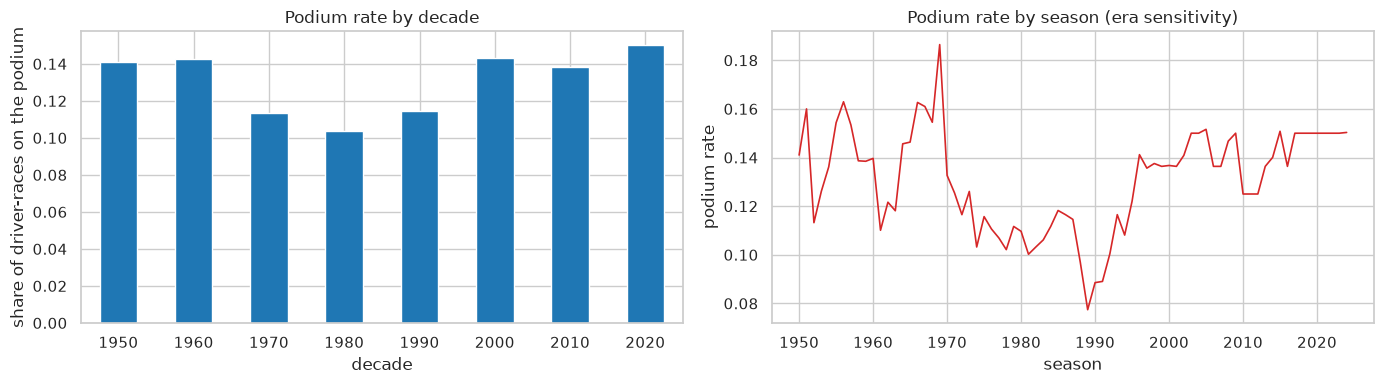

In [116]:
tgt = dedupe_results(res).merge(data["races"][["raceId", "year"]], on="raceId")
tgt["pos_num"] = pd.to_numeric(tgt["positionOrder"].replace(r"\N", np.nan), errors="coerce")
tgt["podium"] = (tgt["pos_num"] <= 3).astype(int)

print(f"rows (unique driver-races): {len(tgt):,}")
print(f"podium finishes            : {tgt['podium'].sum():,}  ({tgt['podium'].mean():.1%})")
print(f"non-podium                 : {(1 - tgt['podium']).sum():,}  ({1 - tgt['podium'].mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

by_decade = tgt.assign(year_n=tgt["year"].astype(int), decade=(tgt["year"].astype(int) // 10) * 10).groupby("decade")["podium"].mean()
by_decade.plot(kind="bar", ax=axes[0], color="#1f77b4")
axes[0].set_title("Podium rate by decade")
axes[0].set_ylabel("share of driver-races on the podium")
axes[0].set_xlabel("decade")
axes[0].tick_params(axis="x", rotation=0)

tgt.assign(year_n=tgt["year"].astype(int)).groupby("year_n")["podium"].mean().plot(ax=axes[1], lw=1.2, color="#d62728")
axes[1].set_title("Podium rate by season (era sensitivity)")
axes[1].set_ylabel("podium rate")
axes[1].set_xlabel("season")
plt.tight_layout()
plt.show()

Rate is low and era-dependent → PR-AUC primary, season-ordered split (`docs/method-notes.md`).


## 10. DE-question inputs

Join checks for Q1–Q3 (answers in §14).


### Q1 inputs

`qualifying.position` vs `results.grid` (penalties split them); compare pre/post-2014.


In [117]:
rq = (data["results"][["raceId", "driverId", "grid"]]
      .merge(data["qualifying"][["raceId", "driverId", "position"]]
             .rename(columns={"position": "quali_position"}), on=["raceId", "driverId"])
      .merge(data["races"][["raceId", "year"]], on="raceId"))

rq["grid_n"] = pd.to_numeric(rq["grid"].replace(r"\N", np.nan), errors="coerce")
rq["quali_n"] = pd.to_numeric(rq["quali_position"].replace(r"\N", np.nan), errors="coerce")
rq["year_n"] = rq["year"].astype(int)
n_all = len(rq)
rq = rq[rq["grid_n"] > 0].copy()          # drop no-start entries (D4)
rq["gap"] = rq["quali_n"] - rq["grid_n"]   # >0: started better than qualified (penalties elsewhere)
rq["era"] = np.where(rq["year_n"] >= 2014, "2014+ hybrid", "pre-2014")

print(f"driver-races with qualifying record : {n_all:,}")
print(f"usable (grid > 0)                   : {len(rq):,}")
print(f"share where grid != qualifying pos  : {(rq['gap'] != 0).mean():.1%}")

display(rq.groupby("era").agg(
    entries=("gap", "size"),
    grid_differs_from_quali=("gap", lambda s: (s != 0).mean()),
    mean_gap=("gap", "mean"),
).round(3))

print("\nexamples where the actual start differs from the qualifying position:")
display(rq[rq["gap"] != 0].sort_values("gap", key=abs, ascending=False).head(8))

driver-races with qualifying record : 10,494
usable (grid > 0)                   : 10,407
share where grid != qualifying pos  : 23.3%


,entries,grid_differs_from_quali,mean_gap
era,,,
2014+ hybrid,4533,0.304,0.042
pre-2014,5874,0.178,0.005



examples where the actual start differs from the qualifying position:


,raceId,driverId,grid,quali_position,year,grid_n,quali_n,year_n,gap,era
5090,864,1,24,1,2012,24,1,2012,-23,pre-2014
5393,877,20,24,3,2012,24,3,2012,-21,pre-2014
8957,1065,822,19,1,2021,19,1,2021,-18,2014+ hybrid
8340,1030,822,20,2,2019,20,2,2019,-18,2014+ hybrid
5836,897,8,22,5,2013,22,5,2013,-17,pre-2014
5625,887,814,21,5,2013,21,5,2013,-16,pre-2014
5128,865,813,24,9,2012,24,9,2012,-15,pre-2014
9438,1089,832,18,3,2022,18,3,2022,-15,2014+ hybrid


### Q2 inputs

`nationality` → `country` sketch (rules D6: `docs/decisions.md`).


In [118]:
COUNTRY_MAP = {
    "American": ["USA", "United States"], "Argentine": ["Argentina"], "Argentinian": ["Argentina"],
    "Australian": ["Australia"], "Austrian": ["Austria"], "Belgian": ["Belgium"],
    "Brazilian": ["Brazil"], "British": ["UK"], "Canadian": ["Canada"], "Chinese": ["China"],
    "Dutch": ["Netherlands"], "East German": ["Germany"], "Finnish": [], "French": ["France"],
    "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"], "Irish": [],
    "Italian": ["Italy"], "Japanese": ["Japan"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "New Zealander": [], "Polish": [], "Portuguese": ["Portugal"],
    "Rhodesian": [], "Russian": ["Russia"], "South African": ["South Africa"], "Spanish": ["Spain"],
    "Swedish": ["Sweden"], "Swiss": ["Switzerland"], "Turkish": [],
}

drivers_home = data["drivers"][["driverId", "nationality"]].copy()
drivers_home["home_countries"] = drivers_home["nationality"].map(COUNTRY_MAP)

unmapped = sorted(set(data["drivers"]["nationality"]) - set(COUNTRY_MAP))
print(f"nationalities in data        : {data['drivers']['nationality'].nunique()}")
print(f"nationalities not yet mapped : {unmapped}")

home = (data["results"][["raceId", "driverId"]]
        .merge(drivers_home, on="driverId")
        .merge(data["races"][["raceId", "circuitId"]], on="raceId")
        .merge(data["circuits"][["circuitId", "country"]], on="circuitId"))
home["home_countries"] = home["home_countries"].map(lambda v: v if isinstance(v, list) else [])
home["is_home"] = home.apply(lambda row: row["country"] in row["home_countries"], axis=1)

print(f"driver-race entries          : {len(home):,}")
print(f"home-country starts          : {int(home['is_home'].sum()):,}  ({home['is_home'].mean():.1%})")

print("\ncircuit countries hosting the most home starts:")
display(home[home["is_home"]].groupby("country").size().sort_values(ascending=False).head(8).to_frame("home_starts"))

nationalities in data        : 43
nationalities not yet mapped : ['American-Italian', 'Argentine-Italian', 'Argentinian ', 'Chilean', 'Colombian', 'Czech', 'Danish', 'Indonesian', 'Liechtensteiner', 'Thai', 'Uruguayan', 'Venezuelan']
driver-race entries          : 26,759
home-country starts          : 2,528  (9.4%)

circuit countries hosting the most home starts:


,home_starts
country,
USA,524
UK,488
Italy,466
France,219
Germany,213
Brazil,119
Belgium,66
Spain,65


### Q3 inputs

Group 139 `status` labels: mechanical vs accident/driver/regulatory (D7).


In [119]:
# Status groups for Q3 (mapping: docs/method-notes.md).
starts = (data["results"].merge(data["status"][["statusId", "status"]], on="statusId")
          .merge(data["races"][["raceId", "year"]], on="raceId"))
status_counts = starts["status"].value_counts()
print(f"distinct statuses in results: {status_counts.size}")
display(status_counts.head(30).to_frame("starts"))

MECHANICAL = {
    "Engine", "Engine fire", "Engine misfire", "Turbo", "Power Unit", "Gearbox", "Transmission",
    "Clutch", "Hydraulics", "Electrical", "Electronics", "Brakes", "Brake duct", "Differential",
    "Drivetrain", "Driveshaft", "Halfshaft", "CV joint", "Axle", "Chassis", "Steering",
    "Track rod", "Suspension", "Handling", "Alternator", "Battery", "Magneto", "Distributor",
    "Ignition", "Spark plugs", "Injection", "Launch control", "Pneumatics", "Exhaust",
    "Crankshaft", "Throttle", "Fuel", "Fuel leak", "Fuel pipe", "Fuel pressure", "Fuel pump",
    "Fuel rig", "Fuel system", "Oil leak", "Oil line", "Oil pipe", "Oil pressure", "Oil pump",
    "Out of fuel", "Water leak", "Water pipe", "Water pressure", "Water pump", "Radiator",
    "Cooling system", "Overheating", "Heat shield fire", "Wheel", "Wheel bearing", "Wheel nut",
    "Wheel rim", "Undertray", "Vibrations", "Mechanical", "Technical", "Power loss",
}
EXCLUDED = {
    "Accident", "Collision", "Collision damage", "Spun off", "Stalled", "Damage", "Debris",
    "Disqualified", "Excluded", "Did not qualify", "Did not prequalify", "Withdrew", "Retired",
    "Not classified", "Not restarted", "Finished", "107% Rule", "Driver unwell", "Illness",
    "Injured", "Injury", "Eye injury", "Fatal accident", "Physical", "Safety", "Safety concerns",
    "Seat", "Driver Seat", "Underweight",
} | {s for s in status_counts.index if s.startswith("+") or s.endswith(" Laps")}
AMBIGUOUS = {"Puncture", "Tyre", "Tyre puncture", "Fire", "Safety belt", "Refuelling"}

classified = pd.Series({s: ("mechanical" if s in MECHANICAL else
                            "excluded" if s in EXCLUDED else
                            "ambiguous" if s in AMBIGUOUS else "unclassified")
                        for s in status_counts.index})
print(classified.value_counts())
print("\nstill unclassified (to decide):")
display(status_counts[classified == "unclassified"].to_frame("starts"))

distinct statuses in results: 137


,starts
status,
Finished,7674
+1 Lap,4037
Engine,2026
+2 Laps,1613
Accident,1062
Did not qualify,1025
Collision,854
Gearbox,810
Spun off,795


mechanical      66
excluded        60
ambiguous        6
unclassified     5
Name: count, dtype: int64

still unclassified (to decide):


,starts
status,
Broken wing,11
Rear wing,10
Front wing,5
Supercharger,5
ERS,5


In [120]:
# Denominator decision D7: a "race start" excludes entries that never started.
starts_ok = starts[~starts["status"].isin({"Did not qualify", "Did not prequalify"})]
starts_ok = starts_ok.assign(
    era=np.where(pd.to_numeric(starts_ok["year"], errors="coerce").between(2014, 2021), "2014-2021",
        np.where(pd.to_numeric(starts_ok["year"], errors="coerce").between(2022, 2024), "2022-2024", "other")),
    mechanical=starts_ok["status"].isin(MECHANICAL),
)
summary = starts_ok.groupby("era").agg(
    starts=("status", "size"),
    mechanical_retirements=("mechanical", "sum"),
).assign(rate=lambda d: (d["mechanical_retirements"] / d["starts"]).round(3))
display(summary)

print("mech rate by constructor (Q3 preview):")
window = starts_ok[starts_ok["era"] != "other"].copy()
by_ctor = (window.merge(data["constructors"][["constructorId", "name"]], on="constructorId")
                 .groupby(["era", "name"])
                 .agg(starts=("status", "size"), mech=("mechanical", "sum")))
by_ctor["rate"] = (by_ctor["mech"] / by_ctor["starts"]).round(3)
display(by_ctor[by_ctor["starts"] >= 30].sort_values("rate", ascending=False).head(8))

,starts,mechanical_retirements,rate
era,,,
2014-2021,3267,310,0.095
2022-2024,1359,81,0.060
other,20777,6170,0.297


mechanical-retirement rate by constructor in the two target windows (preview of Q3, full answer + plot in the DE section):


starts  mech   rate
era       name                               
2014-2021 Caterham            34     8  0.235
          Toro Rosso         242    39  0.161
          Lotus F1            76    11  0.145
          Renault            200    29  0.145
          McLaren            320    44  0.138
2022-2024 Alfa Romeo          88    11  0.125
          Alpine F1 Team     136    15  0.110
2014-2021 Red Bull           320    34  0.106

## 11. Cutoff

After qualifying, before race start. Spec: `docs/leakage.md`; audit below enforces it.


**Leakage spec: `docs/leakage.md`.**


In [121]:
RESULTS_ROLES = {
    "resultId": "identifier", "raceId": "identifier", "driverId": "identifier",
    "constructorId": "pre-race", "number": "pre-race (car number)",
    "grid": "pre-race (set after qualifying + penalties)",
    "podium": "TARGET (derived from positionOrder <= 3)",
}
FORBIDDEN = [
    "position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds",
    "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed", "statusId",
]

audit = pd.DataFrame({"column": list(data["results"].columns) + ["podium"]})
audit["role_at_cutoff"] = audit["column"].map(RESULTS_ROLES).fillna("LEAKAGE - post-race")
display(audit)

assert set(FORBIDDEN) <= set(audit["column"]), "unexpected column name in FORBIDDEN"
assert (audit["role_at_cutoff"].str.startswith("LEAKAGE") ==
        audit["column"].isin(FORBIDDEN)).all(), "leakage audit inconsistent"
print(f"{int(audit['role_at_cutoff'].str.startswith('LEAKAGE').sum())} post-race columns "
      f"excluded from the feature set; target = podium")

,column,role_at_cutoff
0,resultId,identifier
1,raceId,identifier
2,driverId,identifier
3,constructorId,pre-race
4,number,pre-race (car number)
5,grid,pre-race (set after qualifying + penalties)
6,position,LEAKAGE - post-race
7,positionText,LEAKAGE - post-race
8,positionOrder,LEAKAGE - post-race
9,points,LEAKAGE - post-race


12 post-race columns excluded from the feature set; target = podium


## 12. Cleaning (on copies)

Raw files untouched. `\N`→NaN, typing, R2 dedup, flags, taxonomy, before/after EDA. Drop dead weight only (Lab 1 `Cabin` rule); model imputation happens in the train split.


In [122]:
# Phase 2.0: work on copies; \N (+ registered "" in quali q2/q3) -> NaN; strip text
clean = {t: df.copy() for t, df in data.items()}
n_sentinel = 0
for t, df in clean.items():
    n = int((df == r"\N").sum().sum())
    n_sentinel += n
    clean[t] = df.replace(r"\N", np.nan)
n_empty = int((clean["qualifying"][["q2", "q3"]] == "").sum().sum())  # Gate 1.B registry
clean["qualifying"][["q2", "q3"]] = clean["qualifying"][["q2", "q3"]].replace("", np.nan)
for t, df in clean.items():  # 'Argentinian ' -> 'Argentinian' (Q2 hygiene)
    for c in df.columns:  #NB: pandas 3 reads dtype=str as StringDtype, not object
        if pd.api.types.is_string_dtype(df[c]):
            df[c] = df[c].str.strip()
print(f"\\N -> NaN : {n_sentinel:,} cells | '' -> NaN (quali q2/q3): {n_empty} cells")
leftover = sum(int((clean[t] == r"\N").sum().sum()) for t in clean)
assert leftover == 0, "sentinel leftovers found"
print("assert: no literal \\N remains in any cleaned copy")


\N -> NaN : 160,076 cells | '' -> NaN (quali q2/q3): 68 cells
assert: no literal \N remains in any cleaned copy


In [123]:
# Phase 2.1a: calendar dates -> datetime64; race datetime where date+time both exist
for c in ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]:
    clean["races"][c] = pd.to_datetime(clean["races"][c], errors="coerce")
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"], errors="coerce")
has_both = clean["races"]["date"].notna() & clean["races"]["time"].notna() & (clean["races"]["time"] != "")
clean["races"]["race_datetime"] = pd.to_datetime(
    clean["races"]["date"].astype(str) + " " + clean["races"]["time"].astype(str), errors="coerce")
print(clean["races"][["date", "time", "race_datetime"]].dtypes.to_string())
print(f"race_datetime parsed: {int(clean['races']['race_datetime'].notna().sum())} / {len(clean['races'])} races")


date             datetime64[us]
time                        str
race_datetime    datetime64[us]
race_datetime parsed: 394 / 1125 races


quali q1_s: n=10,338, median=87.14s, >200s: 1, <50s: 0
pit duration_s: n=11,371, median=23.61s, >600s (red flags): 460


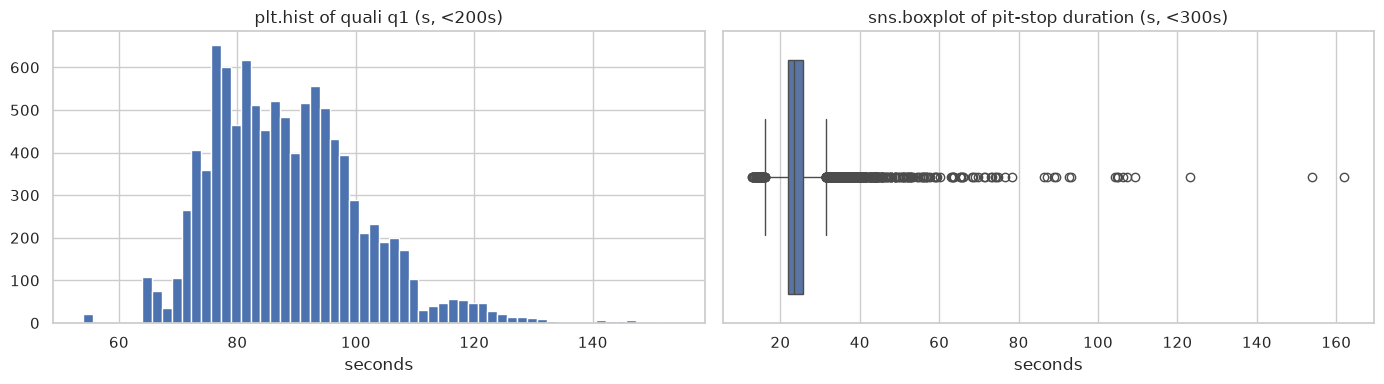

results winners: 1,128 rows, max |parse - ms/1000| = 0.0000s
lap_times: 589,081 rows with both, max |parse - ms/1000| = 0.0000s
Gate 2.A: parsing plausible (outliers flagged, none deleted); unit check passed


In [124]:
# Phase 2.1b: durations (m:ss.mmm / h:mm:ss.mmm / ss.mmm) -> float seconds (new *_s columns)
for c in ["q1", "q2", "q3"]:
    clean["qualifying"][c + "_s"] = clean["qualifying"][c].map(time_to_seconds)
clean["results"]["raceTime_s"] = clean["results"]["time"].map(time_to_seconds)
clean["results"]["fastestLapTime_s"] = clean["results"]["fastestLapTime"].map(time_to_seconds)
clean["lap_times"]["time_s"] = clean["lap_times"]["time"].map(time_to_seconds)
clean["pit_stops"]["duration_s"] = clean["pit_stops"]["duration"].map(time_to_seconds)

# Gate 2.A evidence: plausibility windows (quali laps 50-150 s, stops 15-60 s typical)
q1 = clean["qualifying"]["q1_s"].dropna()
pit = clean["pit_stops"]["duration_s"].dropna()
print(f"quali q1_s: n={len(q1):,}, median={q1.median():.2f}s, >200s: {(q1 > 200).sum()}, <50s: {(q1 < 50).sum()}")
print(f"pit duration_s: n={len(pit):,}, median={pit.median():.2f}s, >600s (red flags): {(pit > 600).sum()}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(q1[q1 < 200], bins=60)
axes[0].set_title("plt.hist of quali q1 (s, <200s)")
axes[0].set_xlabel("seconds")
sns.boxplot(x=pit[pit < 300], ax=axes[1])
axes[1].set_title("sns.boxplot of pit-stop duration (s, <300s)")
axes[1].set_xlabel("seconds")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_05_durations.png", dpi=150)
plt.show()

# Unit check: results.time is a gap except for winners; lap_times are totals.
d = clean["results"]
ms = pd.to_numeric(d["milliseconds"], errors="coerce")
win = d["raceTime_s"].notna() & ms.notna() & (pd.to_numeric(d["positionOrder"], errors="coerce") == 1)
err = (d.loc[win, "raceTime_s"] - ms[win] / 1000).abs()
print(f"results winners: {int(win.sum()):,} rows, max |parse - ms/1000| = {err.max():.4f}s")
assert err.max() < 0.002, "duration/ms mismatch on winners"
d = clean["lap_times"]  # lap times are always totals, so the check holds on all rows
ms = pd.to_numeric(d["milliseconds"], errors="coerce")
both = d["time_s"].notna() & ms.notna()
err = (d.loc[both, "time_s"] - ms[both] / 1000).abs()
print(f"lap_times: {int(both.sum()):,} rows with both, max |parse - ms/1000| = {err.max():.4f}s")
assert err.max() < 0.002, "duration/ms mismatch in lap_times"
print("Gate 2.A: parsing plausible (outliers flagged, none deleted); unit check passed")


In [125]:
# Phase 2.1c: numerics -> nullable dtypes (Int64 / Float64 survive NaN)
def to_num(s, integer=True):
    v = pd.to_numeric(s, errors="coerce")
    return v.astype("Int64") if integer else v.astype("Float64")

INT_BOUND = {"results": ["grid", "position", "positionOrder", "laps", "fastestLap", "rank", "number"],
             "qualifying": ["position", "number"], "lap_times": ["lap", "position"],
             "pit_stops": ["stop", "lap"], "races": ["year", "round"],
             "driver_standings": ["position", "wins"], "constructor_standings": ["position", "wins"],
             "constructor_results": [], "sprint_results": ["grid", "position", "positionOrder", "laps"]}
FLOAT_BOUND = {"results": ["points", "milliseconds", "fastestLapSpeed"],
               "qualifying": [], "lap_times": ["milliseconds"], "pit_stops": ["milliseconds"],
               "driver_standings": ["points"], "constructor_standings": ["points"],
               "constructor_results": ["points"], "sprint_results": ["points", "milliseconds"]}
for t, cols in INT_BOUND.items():
    for c in cols:
        clean[t][c] = to_num(clean[t][c], integer=True)
for t, cols in FLOAT_BOUND.items():
    for c in cols:
        clean[t][c] = to_num(clean[t][c], integer=False)
print(clean["results"][["grid", "position", "positionOrder", "points", "laps", "milliseconds"]].dtypes.to_string())
display(clean["results"][["grid", "positionOrder", "points", "laps"]].describe().round(2))


grid               Int64
position           Int64
positionOrder      Int64
points           Float64
laps               Int64
milliseconds     Float64


,grid,positionOrder,points,laps
count,26759.0,26759.0,26759.0,26759.0
mean,11.13,12.79,1.99,46.3
std,7.2,7.67,4.35,29.5
min,0.0,1.0,0.0,0.0
25%,5.0,6.0,0.0,23.0
50%,11.0,12.0,0.0,53.0
75%,17.0,18.0,2.0,66.0
max,34.0,39.0,50.0,200.0


In [126]:
# Phase 2.1d: categorical normalization (strip done in 2.0; unify circuit aliases here)
print("before:", clean["circuits"]["country"].value_counts().head(6).to_dict())
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})
print("after :", clean["circuits"]["country"].value_counts().head(6).to_dict())
for t, c in [("drivers", "nationality"), ("circuits", "country"), ("constructors", "nationality")]:
    bad = int(clean[t][c].str.contains(r"^\s|\s$", na=False).sum())
    assert bad == 0, f"whitespace remains in {t}.{c}"
print("assert: no leading/trailing whitespace in nationality/country columns")
print(f"'Argentinian ' rows now: {(clean['drivers']['nationality'] == 'Argentinian').sum()} (stripped, -> Argentina in Q2)")


before: {'USA': 11, 'France': 7, 'Spain': 6, 'UK': 4, 'Italy': 4, 'Portugal': 4}
after : {'USA': 12, 'France': 7, 'Spain': 6, 'UK': 4, 'Italy': 4, 'Portugal': 4}
assert: no leading/trailing whitespace in nationality/country columns
'Argentinian ' rows now: 1 (stripped, -> Argentina in Q2)


In [127]:
# Phase 2.1e: Lab-1 Cabin reasoning - drop columns that are mostly baggage and nothing needs
drop_cols = {t: [c for c in df.columns if c == "url"] for t, df in clean.items()}
drop_cols["races"] += ["fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date", "fp3_time",
                       "quali_date", "quali_time"]  # practice/quali wall-clock: never a feature
n_drop = sum(len(v) for v in drop_cols.values())
for t, cols in drop_cols.items():
    clean[t] = clean[t].drop(columns=cols)
print(f"dropped {n_drop} columns: url (4 tables) + races fp*/quali wall-clock (8)")
print("kept: sprint_date + post-race fields (targets/Q3 only, never features)")


dropped 13 columns: url (4 tables) + races fp*/quali wall-clock (8)
kept: sprint_date (weekend-type context, Gate 4.C), all post-race fields (needed for Q3/targets, never as features - see leakage section)


In [128]:
# Phase 2.2: PK/FK re-verified on the CLEANED copies (Gate 2.B evidence)
pk2 = pd.DataFrame([{"table": t, "unique": clean[t].drop_duplicates(c).shape[0] == len(clean[t]),
                     "nulls": int(clean[t][c].isna().sum().sum())}
                    for t, c in PRIMARY_KEYS.items()])
display(pk2)
assert pk2["unique"].all() and pk2["nulls"].eq(0).all(), "PK violation after cleaning"
fk2 = []
for t, fks in FOREIGN_KEYS.items():
    for col, ref_t, ref_c in fks:
        fk2.append({"table": t, "fk": col, "references": f"{ref_t}.{ref_c}",
                    "orphans": int((~clean[t][col].isin(clean[ref_t][ref_c])).sum())})
fk2 = pd.DataFrame(fk2)
display(fk2)
assert fk2["orphans"].eq(0).all(), "FK orphans after cleaning"
no_res = set(clean["races"]["raceId"]) - set(clean["results"]["raceId"])
print(f"PKs unique+non-null; FK orphans: 0; races with no results rows: {len(no_res)} {sorted(no_res) if len(no_res) < 5 else ''}")
print("Gate 2.B: all reconcile on cleaned copies")


,table,unique,nulls
0,circuits,True,0
1,constructors,True,0
2,constructor_results,True,0
3,constructor_standings,True,0
4,drivers,True,0
5,driver_standings,True,0
6,races,True,0
7,results,True,0
8,qualifying,True,0
9,lap_times,True,0


,table,fk,references,orphans
0,constructor_results,raceId,races.raceId,0
1,constructor_results,constructorId,constructors.constructorId,0
2,constructor_standings,raceId,races.raceId,0
3,constructor_standings,constructorId,constructors.constructorId,0
4,driver_standings,raceId,races.raceId,0
5,driver_standings,driverId,drivers.driverId,0
6,races,circuitId,circuits.circuitId,0
7,results,raceId,races.raceId,0
8,results,driverId,drivers.driverId,0
9,results,constructorId,constructors.constructorId,0


PKs unique+non-null; FK orphans: 0; races with no results rows: 0 []
Gate 2.B: all reconcile on cleaned copies


In [129]:
# Phase 2.3: grain R2 - keep the car the driver STARTED in (decided, Decision 3)
def dedupe_results_r2(df):
    tmp = df.copy()
    tmp["_gridn"] = pd.to_numeric(tmp["grid"], errors="coerce")
    tmp["_rid"] = pd.to_numeric(tmp["resultId"], errors="coerce")
    tmp["_pos"] = pd.to_numeric(tmp["positionOrder"], errors="coerce")
    started = tmp[tmp["_gridn"].fillna(0) > 0].sort_values(["_gridn", "_rid"]).drop_duplicates(KEY, keep="first")
    rest = tmp[~tmp.set_index(KEY).index.isin(started.set_index(KEY).index)]
    fallback = rest.sort_values(["_pos"]).drop_duplicates(KEY, keep="first")  # 3 pairs, neither row started
    out = pd.concat([started, fallback])
    return out.drop(columns=["_gridn", "_rid", "_pos"]).sort_index()

clean_results = dedupe_results_r2(clean["results"])
assert not clean_results.duplicated(KEY).any() and len(clean_results) == n_unique
# R1-vs-R2: same 91 rows removed, 17 label flips, all pre-1979
a = pd.to_numeric(modeling_grain.set_index(KEY)["positionOrder"], errors="coerce").sort_index() <= 3
b = pd.to_numeric(clean_results.set_index(KEY)["positionOrder"], errors="coerce").sort_index() <= 3
assert (a.index == b.index).all(), "R1/R2 key sets differ"
delta = int((a.values != b.values).sum())
print(f"R2 applied: {len(clean['results']) - len(clean_results)} rows removed, grain unique ({len(clean_results):,} rows)")
print(f"R1-vs-R2 podium-label delta: {delta} rows ({delta / len(a):.3%}); "
      f"overall podium rate R1 {a.mean():.4f} -> R2 {b.mean():.4f}")
clean["results"] = clean_results


R2 applied: 91 rows removed, grain unique (26,668 rows)
R1-vs-R2 podium-label delta: 17 rows (0.064%); overall podium rate R1 0.1273 -> R2 0.1267


In [130]:
# Phase 2.4: Gate 2.D split + 2.E flags (all derived pre-race info, kept as columns)
r = clean["results"]
r["is_nonstarter"] = (r["grid"] == 0) & (r["laps"] == 0)
r["pitlane_start"] = (r["grid"] == 0) & (r["laps"] > 0)
assert int((r["grid"] == 0).sum()) == int(r["is_nonstarter"].sum() + r["pitlane_start"].sum())
maxgrid = r.groupby("raceId")["grid"].transform("max")
r["grid_eff"] = r["grid"].where(r["grid"] != 0, maxgrid + 1)  # pit-lane ~ back of the grid
r = r.merge(clean["races"][["raceId", "year", "name"]], on="raceId", how="left")
r["is_indy500"] = (r["year"] <= 1960) & r["name"].str.contains("Indianapolis")
clean["results"] = r
print(f"non-starters (excluded from modeling/Q3): {int(r['is_nonstarter'].sum()):,} | "
      f"pit-lane starts (flagged, kept): {int(r['pitlane_start'].sum())} | "
      f"Indy 500 rows (flagged, Q2-excluded): {int(r['is_indy500'].sum())}")


non-starters (excluded from modeling/Q3): 1,563 | pit-lane starts (flagged, kept): 72 | Indy 500 rows (flagged, Q2-excluded): 381


In [131]:
# 2.4b: status taxonomy (D7) -> status_class
STATUS_MECH = (set(MECHANICAL) | {"Supercharger", "ERS"}) - {"Out of fuel"}  # strategy, not failure (plan)
STATUS_AMB = set(AMBIGUOUS) | {"Broken wing", "Rear wing", "Front wing", "Out of fuel", "Retired"}
STATUS_ACC = {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Damage", "Debris"}
STATUS_DRV = {"Driver unwell", "Illness", "Injured", "Injury", "Eye injury", "Physical", "Stalled"}
STATUS_REG = {"Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify",
              "Did not prequalify", "Withdrew", "Not restarted", "Safety concerns", "Safety",
              "Seat", "Driver Seat", "Not classified"}
STATUS_FIN = {"Finished"} | {s for s in clean["status"]["status"] if s.startswith("+")}
STATUS_CLASS = ({s: "mechanical" for s in STATUS_MECH} | {s: "ambiguous" for s in STATUS_AMB} |
                {s: "accident" for s in STATUS_ACC} | {s: "driver" for s in STATUS_DRV} |
                {s: "regulatory" for s in STATUS_REG} | {s: "finished" for s in STATUS_FIN})
observed = set(clean["results"].merge(clean["status"], on="statusId")["status"])
assert observed <= set(STATUS_CLASS), f"unmapped: {observed - set(STATUS_CLASS)}"
clean["results"] = clean["results"].merge(clean["status"], on="statusId", how="left")
clean["results"]["status_class"] = clean["results"]["status"].map(STATUS_CLASS)
print(clean["results"]["status_class"].value_counts().to_frame("entries").T.to_string())
print("\\n'Retired' by era (Gate Q3.A limitation check):")
print(clean["results"].assign(era=np.where(clean["results"]["year"] <= 2013, "<=2013", ">2013"))
        .query("status == 'Retired'").groupby("era").size().to_string())
s = clean["results"][~clean["results"]["is_nonstarter"]]
for era, lo, hi in [("2014-2021", 2014, 2021), ("2022-2024", 2022, 2024)]:
    w = s[s["year"].between(lo, hi)]
    print(f"strict mechanical {era}: {(w['status_class'] == 'mechanical').sum()}/{len(w)} = "
          f"{(w['status_class'] == 'mechanical').mean():.3f}")


status_class  finished  mechanical  accident  regulatory  ambiguous  driver
entries          15115        6438      2771        1944        333      67
\n'Retired' by era (Gate Q3.A limitation check):
era
<=2013    56
>2013     50
strict mechanical 2014-2021: 311/3263 = 0.095
strict mechanical 2022-2024: 80/1356 = 0.059


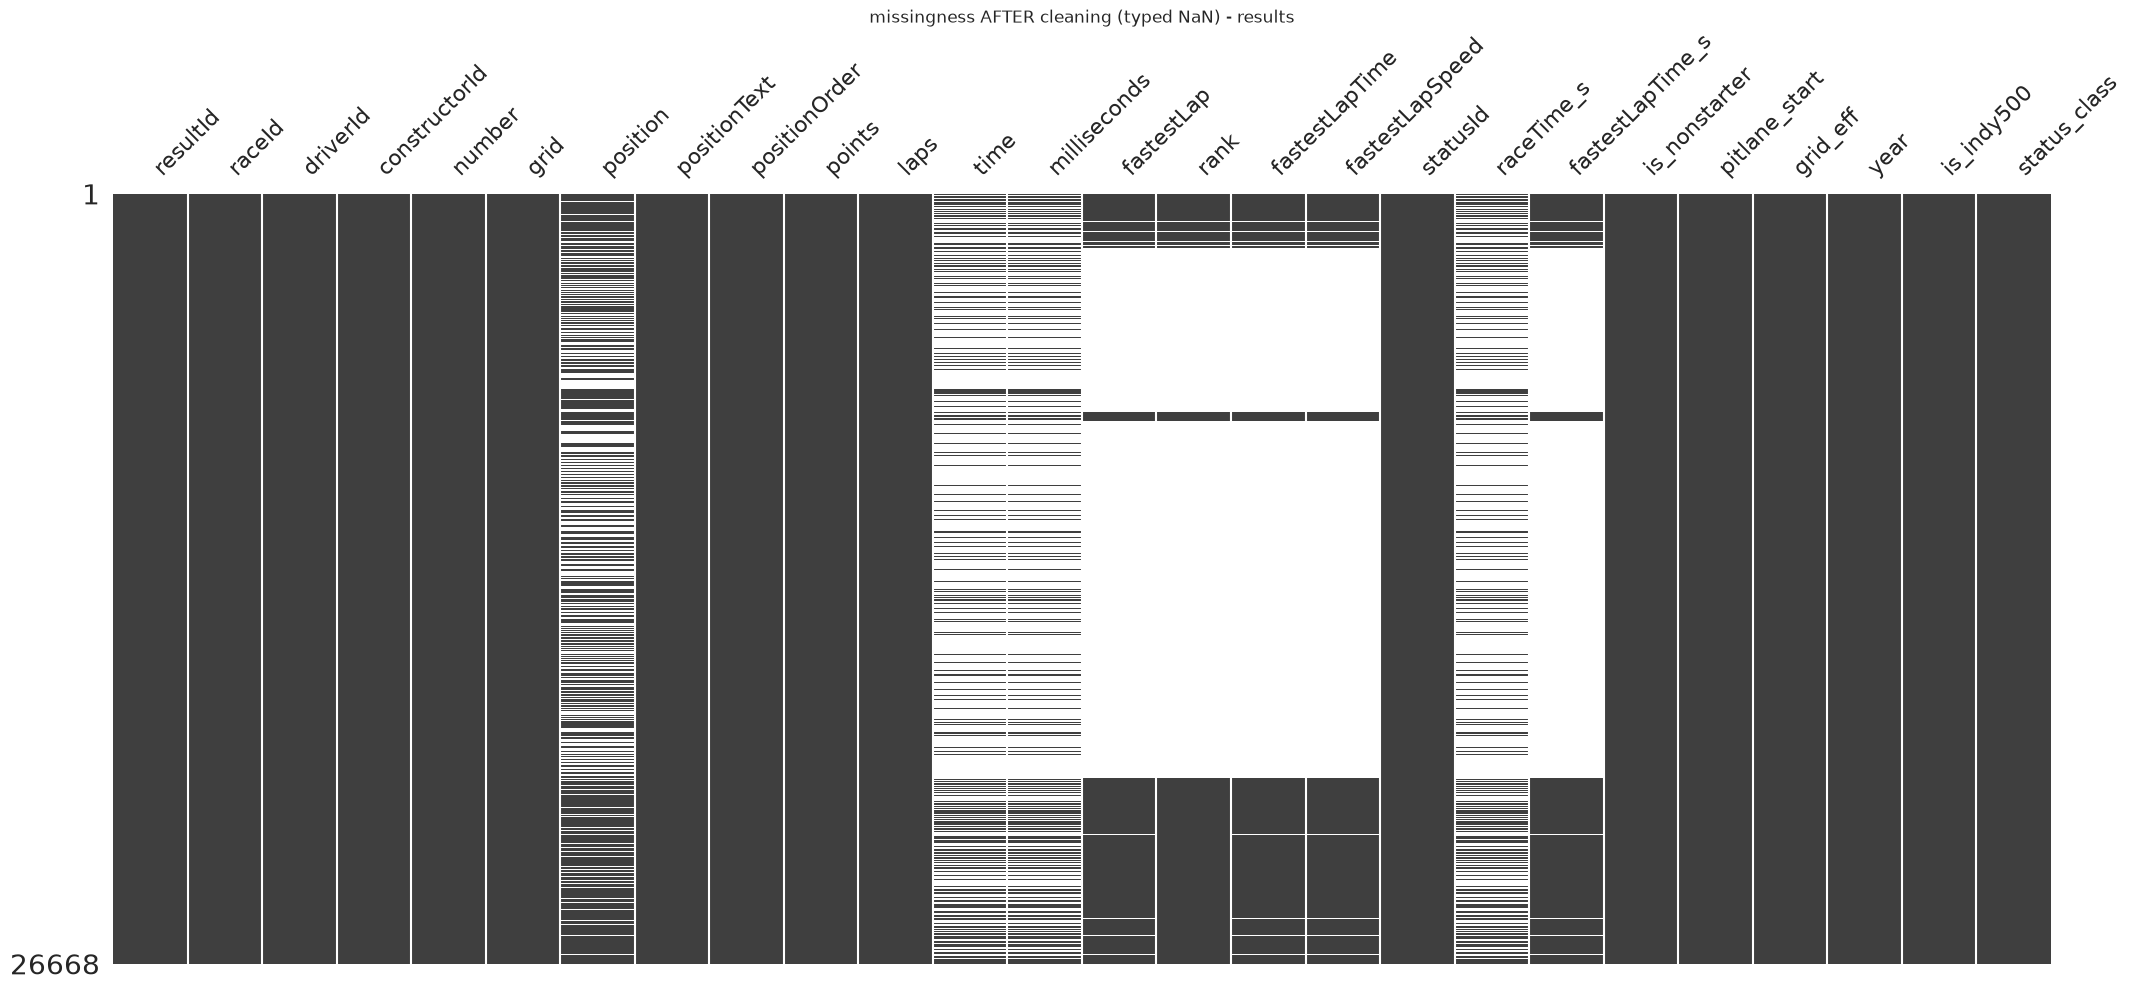

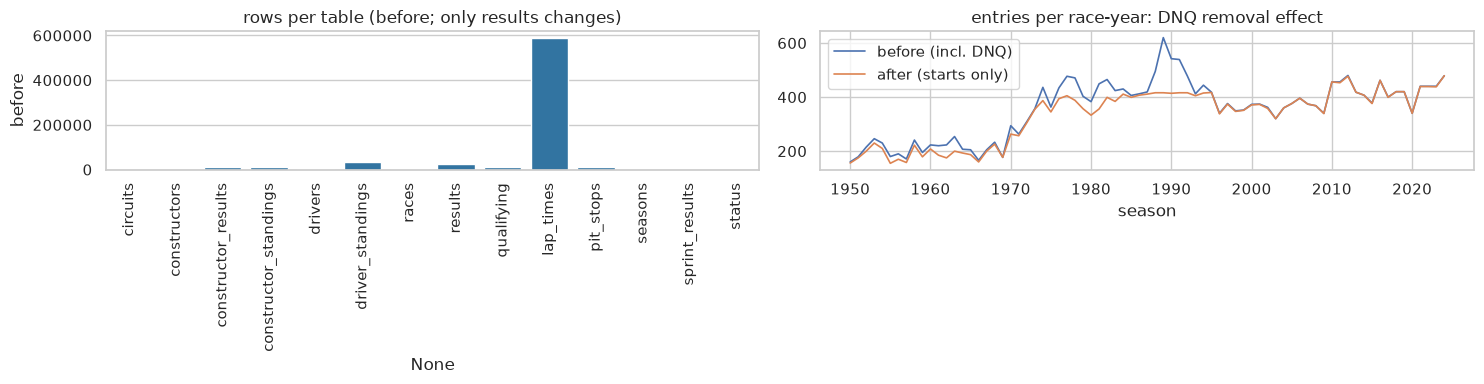

podium rate: raw 0.1269 -> R1 0.1273 -> R2 0.1267 (dedup effect negligible)
\nresults.info() AFTER cleaning (strings -> datetime/int/float/bool):
<class 'pandas.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   resultId          26668 non-null  str    
 1   raceId            26668 non-null  str    
 2   driverId          26668 non-null  str    
 3   constructorId     26668 non-null  str    
 4   number            26662 non-null  Int64  
 5   grid              26668 non-null  Int64  
 6   position          15758 non-null  Int64  
 7   positionText      26668 non-null  str    
 8   positionOrder     26668 non-null  Int64  
 9   points            26668 non-null  Float64
 10  laps              26668 non-null  Int64  
 11  time              7663 non-null   str    
 12  milliseconds      7663 non-null   Float64
 13  fastestLap        8252 non-null   Int64  
 14 

In [132]:
# Phase 2.5: before/after EDA (the brief's required comparison)
msno.matrix(clean["results"].drop(columns=["status", "name"]), sparkline=False)
plt.title("missingness AFTER cleaning (typed NaN) - results")
plt.savefig(FIG_DIR / "fig_06_msno_after.png", dpi=150, bbox_inches="tight")
plt.show()

counts = pd.DataFrame({"before": {t: len(data[t]) for t in TABLES},
                       "after": {t: len(clean[t]) for t in TABLES}})
counts["delta"] = counts["after"] - counts["before"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(x=counts.index, y=counts["before"], ax=axes[0], color="#1f77b4")
axes[0].set_title("rows per table (before; only results changes)")
axes[0].tick_params(axis="x", rotation=90)
e = data["results"].merge(data["races"][["raceId", "year"]].astype({"year": int}), on="raceId")
e["entries"] = 1
before_y = e.groupby(e["year"].astype(int)).size()
a = clean["results"]
after_y = a[~a["is_nonstarter"]].groupby("year").size()
axes[1].plot(before_y.index, before_y.values, lw=1.2, label="before (incl. DNQ)")
axes[1].plot(after_y.index, after_y.values, lw=1.2, label="after (starts only)")
axes[1].set_title("entries per race-year: DNQ removal effect")
axes[1].set_xlabel("season"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_07_rowcounts.png", dpi=150)
plt.show()

r1rate = (pd.to_numeric(modeling_grain["positionOrder"], errors="coerce") <= 3).mean()
r2rate = (pd.to_numeric(clean["results"]["positionOrder"], errors="coerce") <= 3).mean()
print(f"podium rate: raw {pd.to_numeric(res['positionOrder'], errors='coerce').le(3).mean():.4f} -> "
      f"R1 {r1rate:.4f} -> R2 {r2rate:.4f} (dedup effect negligible)")
print("\\nresults.info() AFTER cleaning (strings -> datetime/int/float/bool):")
clean["results"].info()


In [133]:
# Phase 2 wrap: cleaning-impact table (step -> rows -> % -> justification)
N = len(data["results"])
impact = pd.DataFrame([
    ("sentinel -> NaN (+ strip, quali '' -> NaN)", 0, "typing only; no rows touched"),
    ("drop url + fp*/quali wall-clock columns", 0, "12 cols; never features (Lab-1 Cabin rule)"),
    ("R2 dedup (shared drives, pre-1979)", N - n_unique, "one row per (raceId, driverId); 17-label R1 delta noted"),
    ("non-starters flagged (excluded downstream)", int(clean["results"]["is_nonstarter"].sum()), "DNQ/DNPQ/Withdrew, laps=0"),
    ("pit-lane starts flagged (kept, grid_eff)", int(clean["results"]["pitlane_start"].sum()), "laps>0 from grid 0"),
    ("Indy 500 flagged (Q2-excluded)", int(clean["results"]["is_indy500"].sum()), "1950-60 oval, Gate 2.E"),
], columns=["step", "rows", "% / note"])
display(impact)
print("Gates: 2.A parsing plausible + unit check passed | 2.B PK/FK clean, 0 orphans | 2.C R2 applied | "
      "2.D 72 kept-flagged / 1,563 excluded (1,566 pre-dedup) | 2.E Indy flagged")


,step,rows,% / note
0,"sentinel -> NaN (+ strip, quali '' -> NaN)",0,typing only; no rows touched
1,drop url + fp*/quali wall-clock columns,0,12 cols; never features (Lab-1 Cabin rule)
2,"R2 dedup (shared drives, pre-1979)",91,"one row per (raceId, driverId); 17-label R1 de..."
3,non-starters flagged (excluded downstream),1563,"DNQ/DNPQ/Withdrew, laps=0"
4,"pit-lane starts flagged (kept, grid_eff)",72,laps>0 from grid 0
5,Indy 500 flagged (Q2-excluded),381,"1950-60 oval, Gate 2.E"


Gates: 2.A parsing plausible + unit check passed | 2.B PK/FK clean, 0 orphans | 2.C R2 applied | 2.D 72 kept-flagged / 1,563 excluded (1,566 pre-dedup) | 2.E Indy flagged


Gates 2.A–2.E pass (logged D3/D4/D7: `docs/decisions.md`).


## 13. Decision log

Full log D1–D16: `docs/decisions.md` (extended in §14).


In [134]:
DECISIONS = [
    (1, "Raw CSVs immutable; all cleaning on copies", "decided",
     "required by the brief; data/raw/ is never written to"),
    (2, "Grain = one row per (raceId, driverId)", "decided",
     "required by the brief; 85 shared-drive pairs in results"),
    (3, "Dedup = car the driver STARTED in (R2); fallback best posOrder", "decided",
     "Gate 2.C evidence 2026-10-03: 85 pairs, all pre-1979 (61 in 1950-58, last 1978); 22 involve "
     "a podium; R1<->R2 label delta 17/85; 3 pairs have no started-car row -> fallback best posOrder. "
     "R2 = lowest non-zero grid, tie-break first resultId (pre-race view, matches f1.pdf); "
     "modeling window 2003+ so the model itself is unaffected"),
    (4, "grid==0 split: 72 pit-lane starts vs 1,566 non-starters", "decided",
     "Gate 2.D evidence 2026-10-03: grid=0 & laps>0 (72: Finished/+N Laps) = pit-lane start -> flag "
     "+ re-coded grid; grid=0 & laps==0 (1,566: DNQ 1013/DNPQ 331/Withdrew 164, positionText F/W) = "
     "never started -> excluded from modeling and Q3 denominator. Refutes f1.pdf blanket pit-lane claim"),
    (5, "Q1 uses qualifying.position AND results.grid", "decided",
     "grid differs from qualifying position in a non-trivial share of entries (penalties), "
     "and the rate changes by era (section 10.1)"),
    (6, "Q2 mapping: full nationality->country map, 100% coverage asserted", "decided",
     "Phase 3 (14.2): 43 nationalities mapped (hyphenated->first part; non-GP countries map to self, "
     "home=0); circuits USA/United States->USA; 100%-coverage assert in code; Indy 500 excluded "
     "from the primary view (Gate Q2.A)"),
    (7, "Q3 taxonomy: strict mechanical + starts denominator, by constructorId", "decided",
     "Strict mechanical primary, confirmed by Q3.A: broad adds ~1.6pp, rankings stable (rho>0.95). "
     "Wings->ambiguous; Supercharger/ERS->mechanical; Out of fuel->ambiguous. Denominator = starts. "
     "constructorId primary + lineage view. Final: 2014-21 9.5% vs 2022-24 5.9%"),
    (8, "q2/q3 structural missingness pre-2003", "decided",
     "document as coverage limitation; needs era indicator or restricted window (section 8)"),
    (9, "Leakage allow/deny lists", "decided",
     "section 11; sprint_results still excluded by default pending a documented decision"),
    (10, "Split = pdf boundaries on window 2003+: tr 03-19 / val 20-21 / te 22-24", "decided",
     "decided 2026-10-03 per f1.pdf glossary (overrides plan default 03-18/19-21): train 6,831 rows "
     "(963 podiums), val 780 (117), test 1,359 (204) - counts re-verified when the Phase 4 table is built. Gate 6.B: val just under ~1k/150 rule of thumb "
     "-> expanding-window CV inside train for tuning; labs random train_test_split kept as non-primary "
     "comparison (Gate 6.A)"),
    (11, "PR-AUC primary; ROC-AUC + F1@val-threshold secondary", "decided",
     "decided 2026-10-03: base rate 12.7% overall, ~15% modern era -> PR-AUC primary; +Precision/Recall "
     "(the brief's five); Accuracy reference-only (Lab 2: ~87% no-skill, misleading on imbalance)"),
    (12, "Phase 2 cleaning on copies (types, R2, flags, taxonomy)", "decided",
     "2026-10-03, section 12: durations unit-checked (ms/1000), PK/FK 0 orphans, 72 pit-lane kept / "
     "1,566 non-starters out, Indy flagged, strict status taxonomy; impact table + before/after figs"),
]
decisions = pd.DataFrame(DECISIONS, columns=["#", "decision", "status", "rationale / where"])
display(decisions)
print(f"{(decisions['status'] == 'decided').sum()} decided, "
      f"{(decisions['status'] == 'open').sum()} open")

,#,decision,status,rationale / where
0,1,Raw CSVs immutable; all cleaning on copies,decided,required by the brief; data/raw/ is never writ...
1,2,"Grain = one row per (raceId, driverId)",decided,required by the brief; 85 shared-drive pairs i...
2,3,Dedup = car the driver STARTED in (R2); fallba...,decided,"Gate 2.C evidence 2026-10-03: 85 pairs, all pr..."
3,4,"grid==0 split: 72 pit-lane starts vs 1,566 non...",decided,Gate 2.D evidence 2026-10-03: grid=0 & laps>0 ...
4,5,Q1 uses qualifying.position AND results.grid,decided,grid differs from qualifying position in a non...
5,6,Q2 mapping rules (implement in Phase 3),decided,decided 2026-10-03: strip whitespace ('Argenti...
6,7,Q3 taxonomy: strict mechanical + starts denomi...,decided,"decided 2026-10-03: wings (Broken/Rear/Front, ..."
7,8,q2/q3 structural missingness pre-2003,decided,document as coverage limitation; needs era ind...
8,9,Leakage allow/deny lists,decided,section 11; sprint_results still excluded by d...
9,10,Split = pdf boundaries on window 2003+: tr 03-...,decided,decided 2026-10-03 per f1.pdf glossary (overri...


12 decided, 0 open


## 14. Data-engineering answers

Multi-hop joins per question: answer + plot + grain/missingness/cutoff note (details: `docs/phase3.md`).


In [ ]:
# Wilson 95% CI for shares [beyond labs: small-N circuits].
def wilson_interval(successes, trials, confidence=0.95):
    """Computes Wilson score confidence interval for binomial proportions."""
    s = np.asarray(successes, dtype=float)
    n = np.asarray(trials, dtype=float)
    z = stats.norm.ppf(1 - (1 - confidence) / 2)
    p_hat = np.where(n > 0, s / n, 0.0)
    denominator = 1 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denominator
    margin = (z / denominator) * np.sqrt(np.where(n > 0, (p_hat * (1 - p_hat) / n) + (z**2 / (4 * n**2)), 0.0))
    low = np.clip(center - margin, 0.0, 1.0)
    high = np.clip(center + margin, 0.0, 1.0)
    if np.ndim(successes) == 0 and np.ndim(trials) == 0:
        return float(p_hat), float(low), float(high)
    return p_hat, low, high

print("Wilson score interval helper defined. Test 10/10:", wilson_interval(10, 10))

Wilson score interval helper defined. Test 10/10: (array(1.), np.float64(0.7224672001371107), np.float64(1.0))


### 14.1 Q1: front-row → podium by circuit

Grid front row (1950–2024) + quali front row (2003+); pre/post-2014; k≥10 filter (gates Q1.A/B: `docs/phase3.md`).


In [ ]:
# Q1 Multi-hop joins with explicit grain checks
n_init = len(clean["results"])
q1_df = clean["results"].merge(
    clean["races"][["raceId", "year", "name", "circuitId"]].rename(columns={"name": "race_name"}),
    on="raceId", how="inner"
)
assert len(q1_df) == n_init, "Grain altered after races merge"

q1_df = q1_df.merge(
    clean["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"}),
    on="circuitId", how="inner"
)
assert len(q1_df) == n_init, "Grain altered after circuits merge"

q1_df = q1_df.merge(
    clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
    on=["raceId", "driverId"], how="left"
)
assert len(q1_df) == n_init, "Grain altered after qualifying merge"

q1_df["year"] = q1_df["year"].astype(int)
q1_df["podium"] = (q1_df["positionOrder"] <= 3).astype(int)
q1_df["grid_fr"] = q1_df["grid"].isin([1, 2])
q1_df["quali_fr"] = q1_df["quali_pos"].isin([1, 2])
q1_df["era"] = np.where(q1_df["year"] >= 2014, "2014+ (Turbo-Hybrid)", "Pre-2014")

print(f"Total driver-race entries analyzed: {len(q1_df):,}")
print(f"Total grid front-row starts: {q1_df['grid_fr'].sum():,}")
print(f"Total qualifying front-row starts: {q1_df['quali_fr'].sum():,}")

# Overall conversion comparison
overall_q1 = []
for era in ["Pre-2014", "2014+ (Turbo-Hybrid)"]:
    sub = q1_df[q1_df["era"] == era]
    g_fr = sub[sub["grid_fr"]]
    q_fr = sub[sub["quali_fr"]]
    g_rate, g_low, g_high = wilson_interval(g_fr["podium"].sum(), len(g_fr))
    q_rate, q_low, q_high = wilson_interval(q_fr["podium"].sum(), len(q_fr))
    overall_q1.append({
        "era": era,
        "grid_starts": len(g_fr), "grid_podiums": int(g_fr["podium"].sum()), "grid_conv_rate": round(g_rate, 4),
        "grid_95ci": f"[{g_low:.3f}, {g_high:.3f}]",
        "quali_starts": len(q_fr), "quali_podiums": int(q_fr["podium"].sum()), "quali_conv_rate": round(q_rate, 4),
        "quali_95ci": f"[{q_low:.3f}, {q_high:.3f}]"
    })
df_q1_overall = pd.DataFrame(overall_q1).set_index("era")
display(df_q1_overall)

Total driver-race entries analyzed: 26,668
Total grid front-row starts: 2,259
Total qualifying front-row starts: 988


,grid_starts,grid_podiums,grid_conv_rate,grid_95ci,quali_starts,quali_podiums,quali_conv_rate,quali_95ci
era,,,,,,,,
Pre-2014,1805,1002,0.5551,"[0.532, 0.578]",532,344,0.6466,"[0.605, 0.686]"
2014+ (Turbo-Hybrid),454,345,0.7599,"[0.719, 0.797]",456,336,0.7368,"[0.695, 0.775]"


Circuits meeting threshold (k >= 10 in both eras): 16
Circuits excluded due to small sample size (< 10 in either era): 61


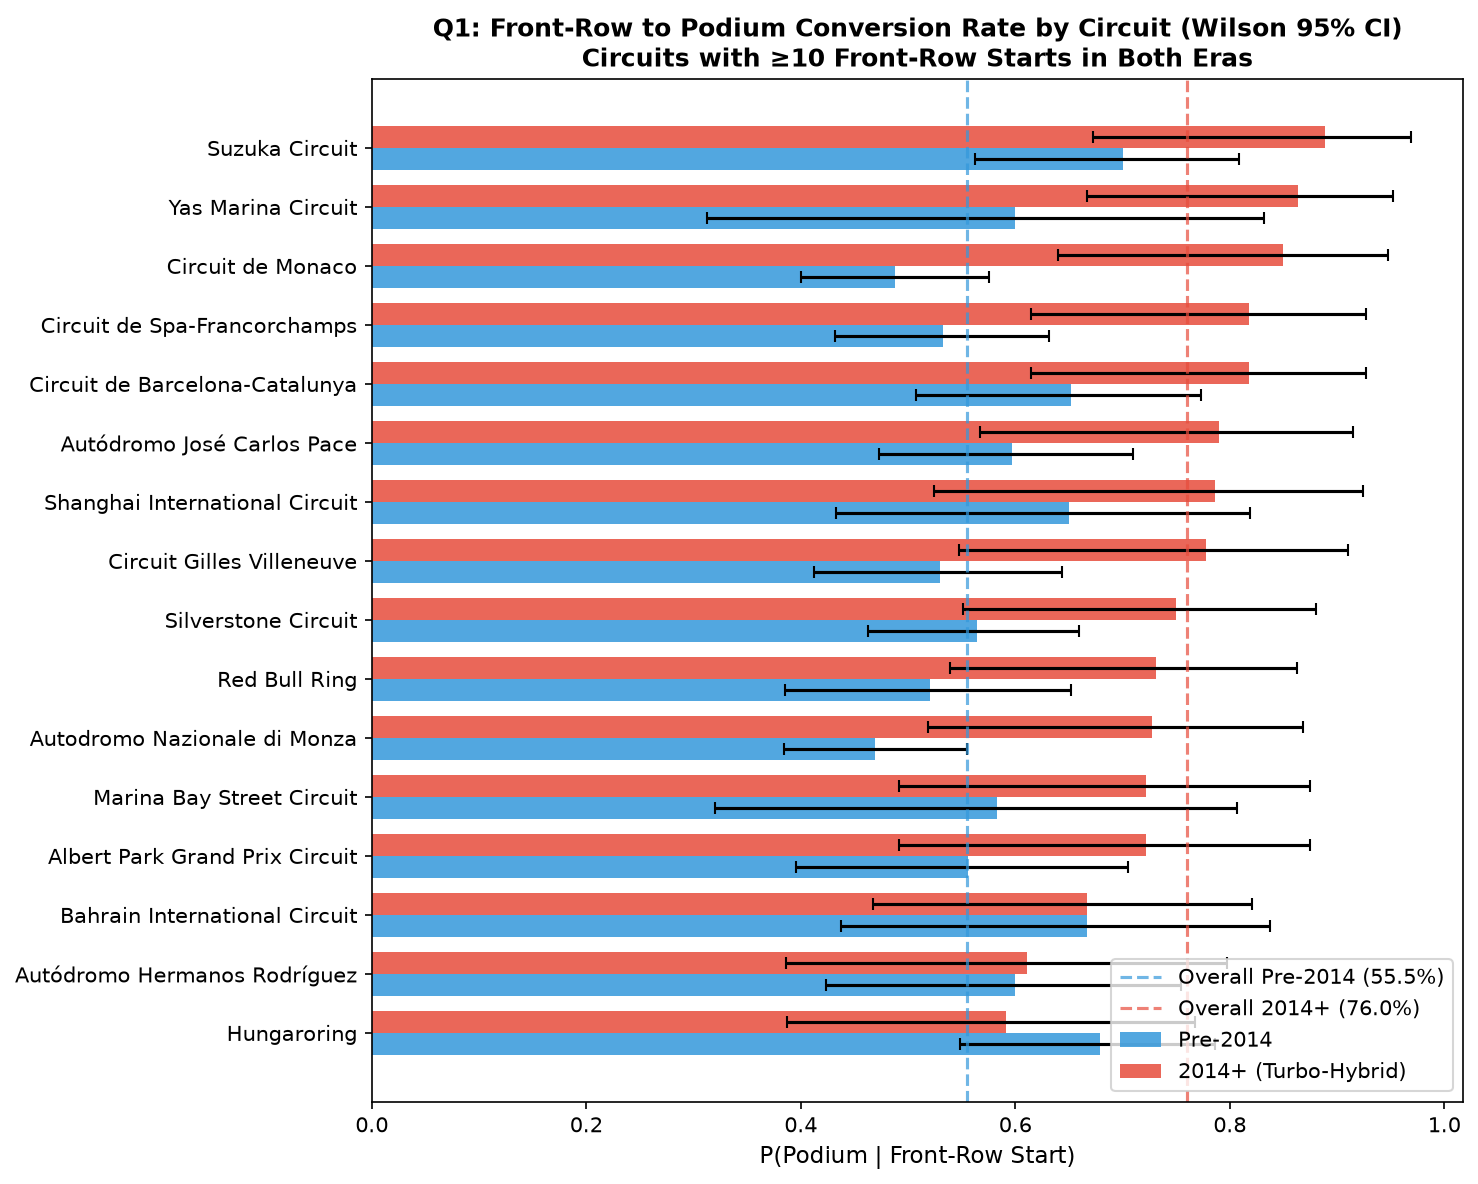

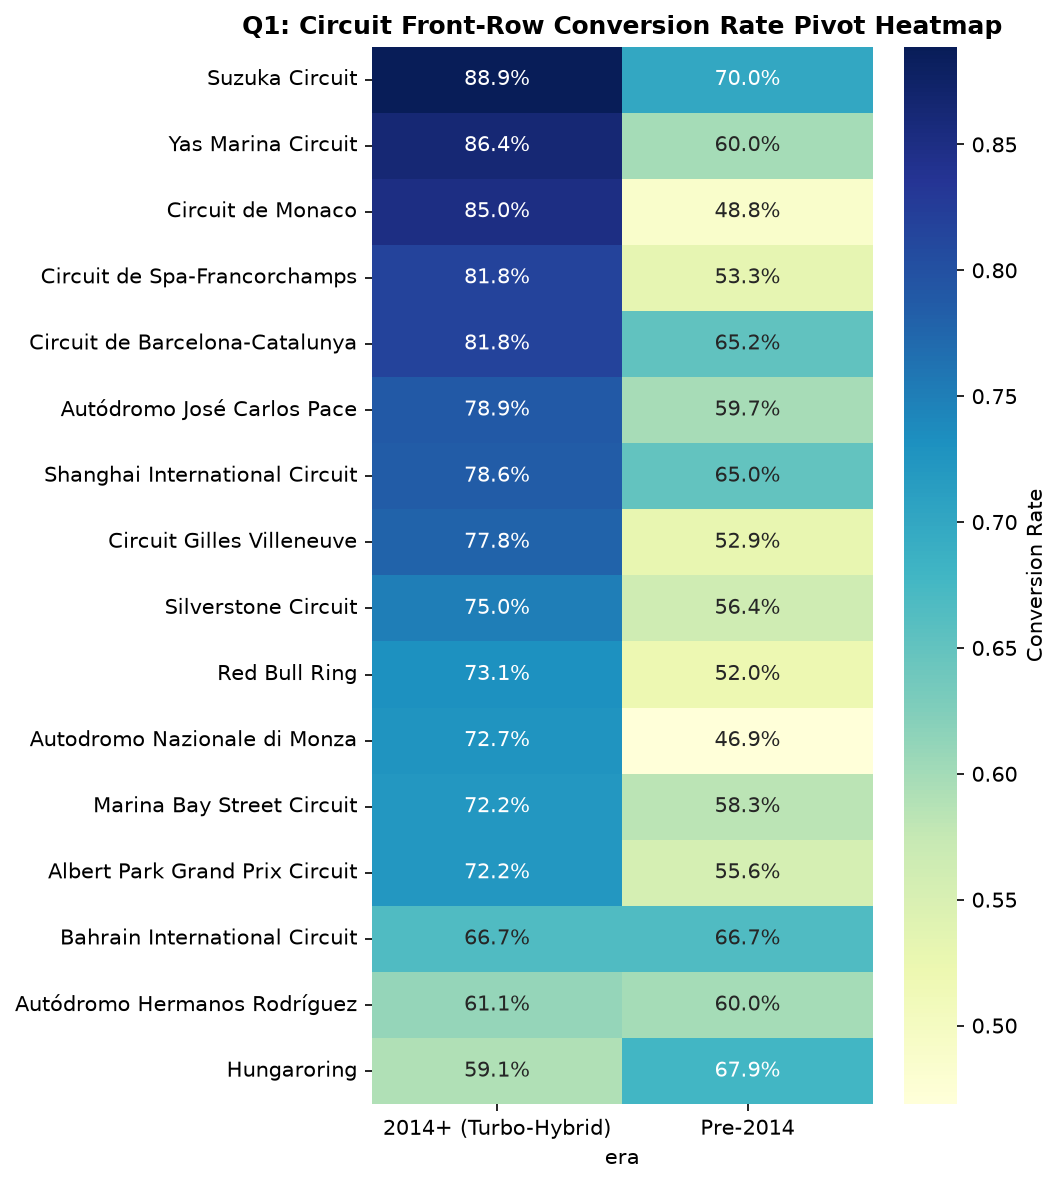

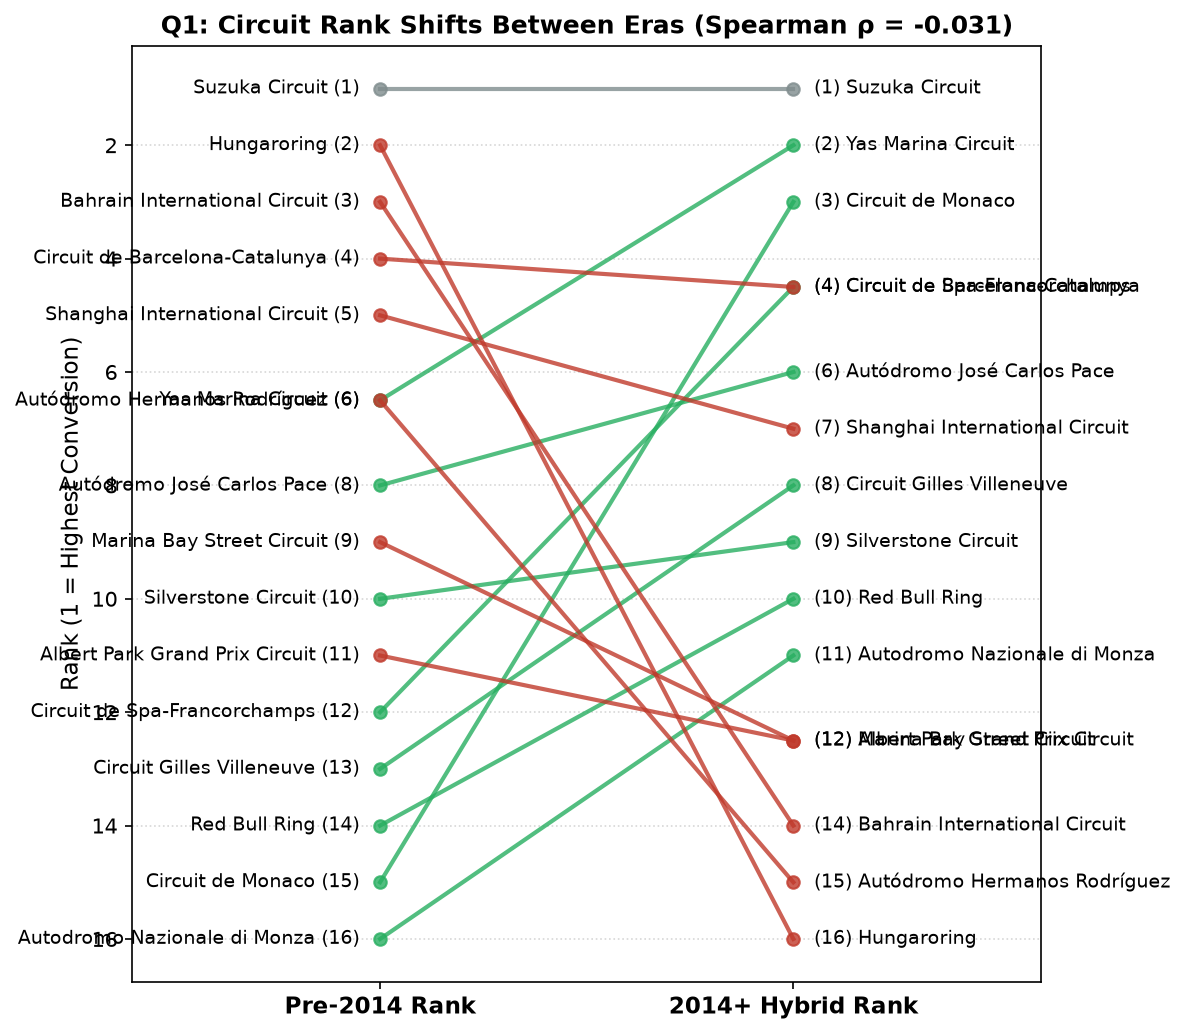

Spearman rank correlation between eras: -0.031


era,Pre-2014,2014+ (Turbo-Hybrid),Rank Pre-2014,Rank 2014+
circuit_name,,,,
Suzuka Circuit,0.700,0.889,1.0,1.0
Yas Marina Circuit,0.600,0.864,6.5,2.0
Circuit de Monaco,0.488,0.850,15.0,3.0
Circuit de Spa-Francorchamps,0.533,0.818,12.0,4.5
Circuit de Barcelona-Catalunya,0.652,0.818,4.0,4.5
Autódromo José Carlos Pace,0.597,0.789,8.0,6.0
Shanghai International Circuit,0.650,0.786,5.0,7.0
Circuit Gilles Villeneuve,0.529,0.778,13.0,8.0
Silverstone Circuit,0.564,0.750,10.0,9.0


In [ ]:
# Gate Q1.B: Filter circuits with >= 10 front-row starts in both eras
circ_counts = q1_df[q1_df["grid_fr"]].groupby(["circuit_name", "era"]).size().unstack(fill_value=0)
common_circuits = circ_counts[(circ_counts["Pre-2014"] >= 10) & (circ_counts["2014+ (Turbo-Hybrid)"] >= 10)].index.tolist()
excluded_circuits = circ_counts[~circ_counts.index.isin(common_circuits)]

print(f"Circuits meeting threshold (k >= 10 in both eras): {len(common_circuits)}")
print(f"Circuits excluded due to small sample size (< 10 in either era): {len(excluded_circuits)}")

circ_stats = q1_df[q1_df["grid_fr"] & q1_df["circuit_name"].isin(common_circuits)].groupby(["circuit_name", "era"])["podium"].agg(["sum", "count"]).reset_index()
rate, low, high = wilson_interval(circ_stats["sum"], circ_stats["count"])
circ_stats["rate"] = rate
circ_stats["ci_low"] = low
circ_stats["ci_high"] = high
circ_stats["err_low"] = rate - low
circ_stats["err_high"] = high - rate
# Era averages from the table above (never hardcoded): recompute-proof.
overall_pre = float(df_q1_overall.loc["Pre-2014", "grid_conv_rate"])
overall_post = float(df_q1_overall.loc["2014+ (Turbo-Hybrid)", "grid_conv_rate"])

# Plot fig_08: Grouped bar chart with Wilson CIs
order = circ_stats[circ_stats["era"] == "2014+ (Turbo-Hybrid)"].sort_values("rate", ascending=True)["circuit_name"].tolist()

fig, ax = plt.subplots(figsize=(10, 8))
y_pos = np.arange(len(order))
height = 0.38

pre_data = circ_stats[circ_stats["era"] == "Pre-2014"].set_index("circuit_name").loc[order]
post_data = circ_stats[circ_stats["era"] == "2014+ (Turbo-Hybrid)"].set_index("circuit_name").loc[order]

ax.barh(y_pos - height/2, pre_data["rate"], height=height, label="Pre-2014", color="#3498db", alpha=0.85,
        xerr=[pre_data["err_low"], pre_data["err_high"]], capsize=3)
ax.barh(y_pos + height/2, post_data["rate"], height=height, label="2014+ (Turbo-Hybrid)", color="#e74c3c", alpha=0.85,
        xerr=[post_data["err_low"], post_data["err_high"]], capsize=3)

ax.set_yticks(y_pos)
ax.set_yticklabels(order, fontsize=10)
ax.set_xlabel("P(Podium | Front-Row Start)", fontsize=11)
ax.set_title("Q1: Front-Row to Podium Conversion Rate by Circuit (Wilson 95% CI)\nCircuits with ≥10 Front-Row Starts in Both Eras", fontsize=12, fontweight="bold")
ax.axvline(overall_pre, color="#3498db", linestyle="--", alpha=0.7, label=f"Overall Pre-2014 ({overall_pre:.1%})")
ax.axvline(overall_post, color="#e74c3c", linestyle="--", alpha=0.7, label=f"Overall 2014+ ({overall_post:.1%})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_08_q1_conversion_bars.png", dpi=150)
plt.show()

# Plot fig_09: Pivot Heatmap
piv_heat = circ_stats.pivot(index="circuit_name", columns="era", values="rate").loc[order[::-1]]
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(piv_heat, annot=True, fmt=".1%", cmap="YlGnBu", cbar_kws={"label": "Conversion Rate"}, ax=ax)
ax.set_title("Q1: Circuit Front-Row Conversion Rate Pivot Heatmap", fontsize=12, fontweight="bold")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_09_q1_heatmap_pivot.png", dpi=150)
plt.show()

# Plot fig_10: Rank Change Chart
ranked = piv_heat.copy()
ranked["Rank Pre-2014"] = ranked["Pre-2014"].rank(ascending=False)
ranked["Rank 2014+"] = ranked["2014+ (Turbo-Hybrid)"].rank(ascending=False)
spearman_corr = ranked[["Rank Pre-2014", "Rank 2014+"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(8, 7))
for circ in ranked.index:
    r_pre = ranked.loc[circ, "Rank Pre-2014"]
    r_post = ranked.loc[circ, "Rank 2014+"]
    color = "#27ae60" if r_post < r_pre else "#c0392b" if r_post > r_pre else "#7f8c8d"
    ax.plot([0, 1], [r_pre, r_post], marker="o", color=color, lw=2, alpha=0.8)
    ax.text(-0.05, r_pre, f"{circ} ({r_pre:.0f})", ha="right", va="center", fontsize=9)
    ax.text(1.05, r_post, f"({r_post:.0f}) {circ}", ha="left", va="center", fontsize=9)

ax.set_xlim(-0.6, 1.6)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Pre-2014 Rank", "2014+ Hybrid Rank"], fontsize=11, fontweight="bold")
ax.invert_yaxis()
ax.set_ylabel("Rank (1 = Highest Conversion)", fontsize=11)
ax.set_title(f"Q1: Circuit Rank Shifts Between Eras (Spearman ρ = {spearman_corr:.3f})", fontsize=12, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_10_q1_rank_change.png", dpi=150)
plt.show()

print(f"Spearman rank correlation between eras: {spearman_corr:.3f}")
display(ranked[["Pre-2014", "2014+ (Turbo-Hybrid)", "Rank Pre-2014", "Rank 2014+"]].round(3))

**Answer:** conversion 55.5% → 76.0%; top 2014+: Suzuka 88.9%, Yas Marina 86.4%, Monaco 85.0%; rank order reshuffled (ρ≈0). Details: `docs/phase3.md`.


### 14.2 Q2: home-country effect

Stratified (Lab 1) + logistic regression (Lab 2) on grid bins; Indy 500 excluded (details: `docs/phase3.md`).


In [ ]:
# Nationality -> country (assert 100% coverage below).
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina",
    "Argentine-Italian": "Argentina", "Argentinian": "Argentina", "Australian": "Australia",
    "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China",
    "Colombian": "Colombia", "Czech": "Czech Republic", "Danish": "Denmark",
    "Dutch": "Netherlands", "East German": "Germany", "Finnish": "Finland",
    "French": "France", "German": "Germany", "Hungarian": "Hungary",
    "Indian": "India", "Indonesian": "Indonesia", "Irish": "Ireland",
    "Italian": "Italy", "Japanese": "Japan", "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal",
    "Rhodesian": "Rhodesia", "Russian": "Russia", "South African": "South Africa",
    "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
    "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}

# Unit check: assert 100% coverage
drivers_nat = clean["drivers"]["nationality"].astype(str).str.strip()
unmapped = set(drivers_nat.unique()) - set(NATIONALITY_TO_COUNTRY.keys())
assert len(unmapped) == 0, f"Unmapped nationalities found: {unmapped}"
print("Nationality mapping coverage: 100.0% (0 unmapped)")

# Multi-hop joins on starts only
q2_df = clean["results"][~clean["results"]["is_nonstarter"]].copy()
n_q2_starts = len(q2_df)
q2_df = q2_df.merge(clean["drivers"][["driverId", "nationality"]], on="driverId", how="inner")
assert len(q2_df) == n_q2_starts, "Grain altered after drivers merge"

q2_df = q2_df.merge(clean["races"][["raceId", "year", "circuitId"]], on="raceId", how="inner")
assert len(q2_df) == n_q2_starts, "Grain altered after races merge"

q2_df = q2_df.merge(clean["circuits"][["circuitId", "country"]].rename(columns={"country": "circuit_country"}), on="circuitId", how="inner")
assert len(q2_df) == n_q2_starts, "Grain altered after circuits merge"

q2_df["driver_country"] = q2_df["nationality"].astype(str).str.strip().map(NATIONALITY_TO_COUNTRY)
q2_df["is_home"] = (q2_df["driver_country"] == q2_df["circuit_country"]).astype(int)
q2_df["podium"] = (q2_df["positionOrder"] <= 3).astype(int)
q2_df["year"] = q2_df["year"].astype(int)
q2_df["grid_bin"] = pd.cut(q2_df["grid_eff"], bins=[0, 1, 3, 6, 10, 100], labels=["1 (Pole)", "2-3", "4-6", "7-10", "11+"])

# Exclude Indy 500 for primary view
q2_main = q2_df[~q2_df["is_indy500"]].copy()
print(f"Total starts analyzed (excl. Indy 500): {len(q2_main):,}")
print(f"Home starts: {q2_main['is_home'].sum():,} ({q2_main['is_home'].mean():.2%}) | Away starts: {(q2_main['is_home']==0).sum():,}")

Nationality mapping coverage: 100.0% (0 unmapped)
Total starts analyzed (excl. Indy 500): 24,724
Home starts: 1,944 (7.86%) | Away starts: 22,780


,Away Podium Rate,Home Podium Rate,Difference (H - A),Home Starts,Away Starts,Home Weight
grid_bin,,,,,,
1 (Pole),0.6423,0.5833,-0.0590,84,1040,0.0432
2-3,0.5087,0.5374,0.0288,147,2078,0.0756
4-6,0.2601,0.2643,0.0042,227,3114,0.1168
7-10,0.0921,0.0714,-0.0206,336,4117,0.1728
11+,0.0164,0.0104,-0.0060,1150,12431,0.5916


Grid-Weighted Average Difference: -0.0070 (-0.70 percentage points)


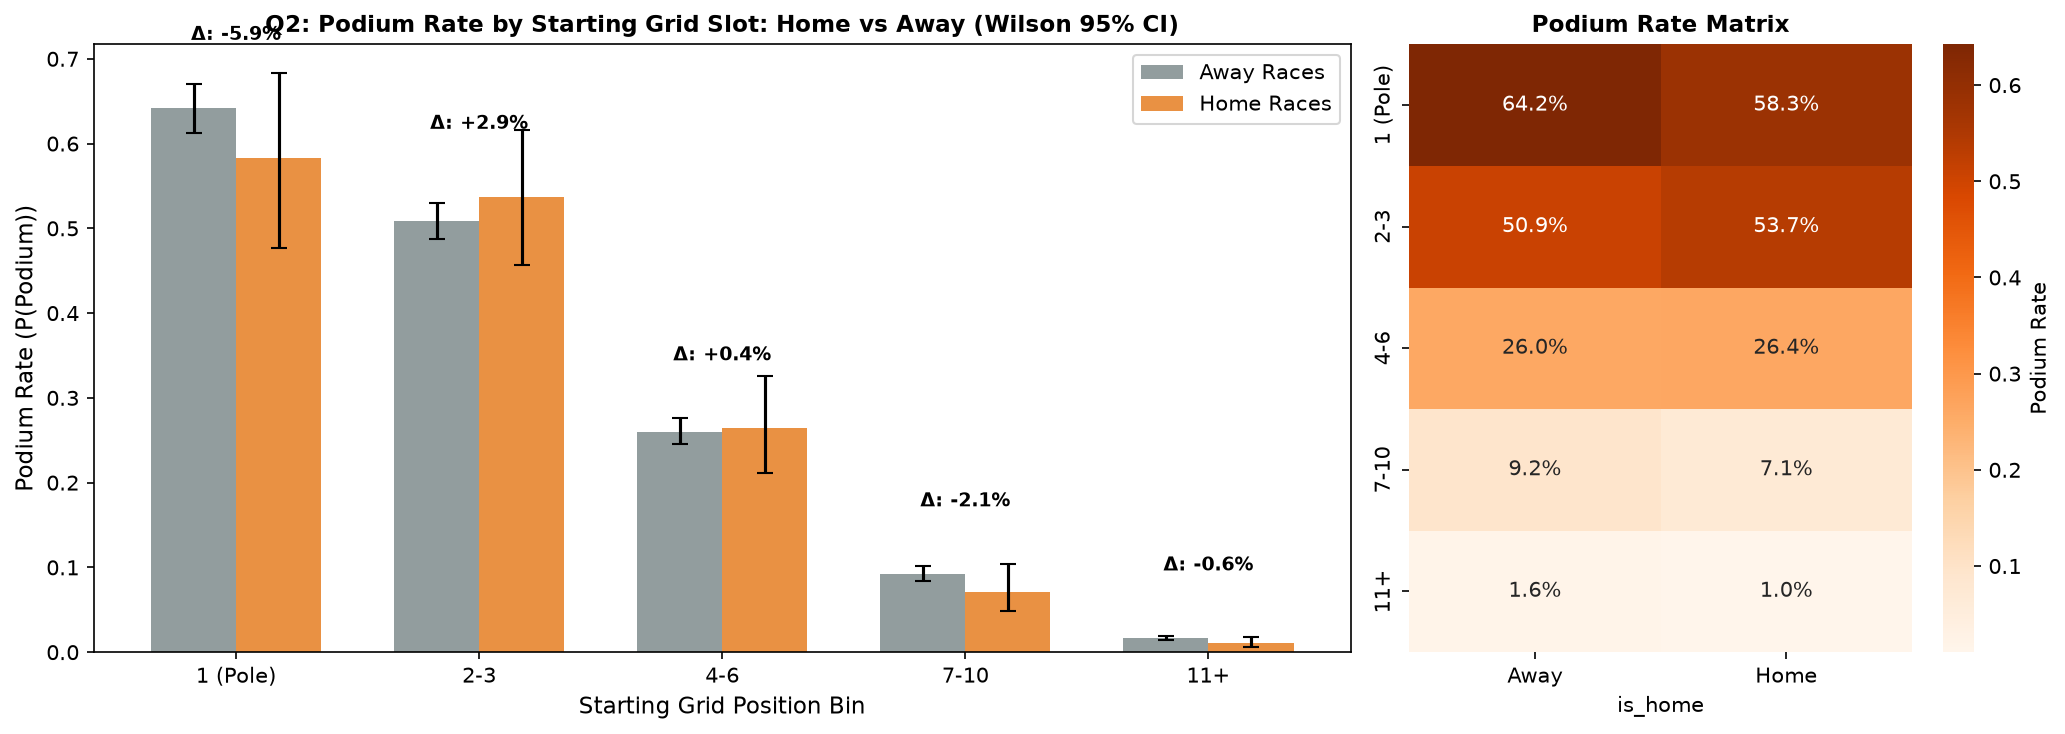

Logistic Regression Home Odds Ratio: 0.9149
Cluster Bootstrap 95% CI: [0.7851, 1.0817] (Spans 1.0: True)


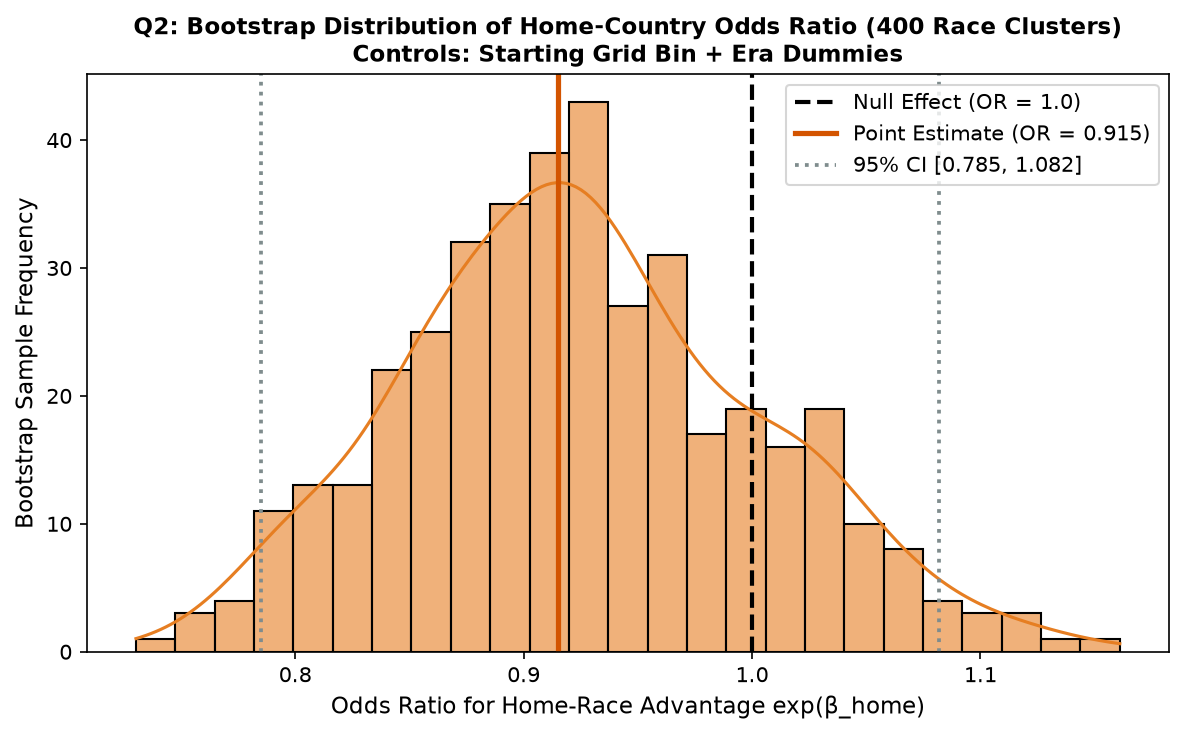

In [ ]:
# Approach 1: Stratified Comparison
piv_mean = q2_main.pivot_table(index="grid_bin", columns="is_home", values="podium", aggfunc="mean", observed=False)
piv_count = q2_main.pivot_table(index="grid_bin", columns="is_home", values="podium", aggfunc="count", observed=False)
diff = piv_mean[1] - piv_mean[0]
weights = piv_count[1] / piv_count[1].sum()
weighted_diff = (diff * weights).sum()

summary_strat = pd.DataFrame({
    "Away Podium Rate": piv_mean[0], "Home Podium Rate": piv_mean[1],
    "Difference (H - A)": diff, "Home Starts": piv_count[1],
    "Away Starts": piv_count[0], "Home Weight": weights
})
display(summary_strat.round(4))
print(f"Grid-Weighted Average Difference: {weighted_diff:+.4f} ({weighted_diff*100:+.2f} percentage points)")

# Plot fig_11: Grouped bar chart + Heatmap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})

bins = piv_mean.index.tolist()
x = np.arange(len(bins))
w = 0.35

rate_away, low_a, high_a = wilson_interval(piv_mean[0] * piv_count[0], piv_count[0])
rate_home, low_h, high_h = wilson_interval(piv_mean[1] * piv_count[1], piv_count[1])

ax1.bar(x - w/2, piv_mean[0], width=w, label="Away Races", color="#7f8c8d", alpha=0.85,
        yerr=[rate_away - low_a, high_a - rate_away], capsize=4)
ax1.bar(x + w/2, piv_mean[1], width=w, label="Home Races", color="#e67e22", alpha=0.85,
        yerr=[rate_home - low_h, high_h - rate_home], capsize=4)

for i in range(len(bins)):
    gap = diff.iloc[i] * 100
    ax1.text(x[i], max(piv_mean.iloc[i]) + 0.08, f"Δ: {gap:+.1f}%", ha="center", fontsize=9, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(bins, fontsize=10)
ax1.set_xlabel("Starting Grid Position Bin", fontsize=11)
ax1.set_ylabel("Podium Rate (P(Podium))", fontsize=11)
ax1.set_title("Q2: Podium Rate by Starting Grid Slot: Home vs Away (Wilson 95% CI)", fontsize=11, fontweight="bold")
ax1.legend()

# Heatmap
heat_data = piv_mean.rename(columns={0: "Away", 1: "Home"})
sns.heatmap(heat_data, annot=True, fmt=".1%", cmap="Oranges", ax=ax2, cbar_kws={"label": "Podium Rate"})
ax2.set_title("Podium Rate Matrix", fontsize=11, fontweight="bold")
ax2.set_ylabel("")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_11_q2_stratified_bars.png", dpi=150)
plt.show()

# Approach 2: Logistic Regression with Cluster Bootstrap
q2_main["era"] = pd.cut(q2_main["year"], bins=[1949, 1979, 2013, 2030], labels=["pre-1980", "1980-2013", "2014+"])
X_cols = pd.get_dummies(q2_main[["is_home", "grid_bin", "era"]], drop_first=True)
y_all = q2_main["podium"]

lr = LogisticRegression(max_iter=1000, C=1e5)
lr.fit(X_cols, y_all)
home_coef = lr.coef_[0][0]
home_or = np.exp(home_coef)

np.random.seed(42)
unique_races = q2_main["raceId"].unique()
boot_ors = []
for _ in range(400):
    sample_races = pd.DataFrame({"raceId": np.random.choice(unique_races, size=len(unique_races), replace=True)})
    sample_df = sample_races.merge(q2_main, on="raceId", how="inner")
    X_b = pd.get_dummies(sample_df[["is_home", "grid_bin", "era"]], drop_first=True).reindex(columns=X_cols.columns, fill_value=0)
    lr_b = LogisticRegression(max_iter=500, C=1e5)
    lr_b.fit(X_b, sample_df["podium"])
    boot_ors.append(np.exp(lr_b.coef_[0][0]))

ci_low, ci_high = np.percentile(boot_ors, [2.5, 97.5])
print(f"Logistic Regression Home Odds Ratio: {home_or:.4f}")
print(f"Cluster Bootstrap 95% CI: [{ci_low:.4f}, {ci_high:.4f}] (Spans 1.0: {ci_low <= 1.0 <= ci_high})")

# Plot fig_12: Bootstrap distribution
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(boot_ors, kde=True, color="#e67e22", ax=ax, bins=25, alpha=0.6)
ax.axvline(1.0, color="black", linestyle="--", lw=2, label="Null Effect (OR = 1.0)")
ax.axvline(home_or, color="#d35400", lw=2.5, label=f"Point Estimate (OR = {home_or:.3f})")
ax.axvline(ci_low, color="#7f8c8d", linestyle=":", lw=1.8, label=f"95% CI [{ci_low:.3f}, {ci_high:.3f}]")
ax.axvline(ci_high, color="#7f8c8d", linestyle=":", lw=1.8)
ax.set_xlabel("Odds Ratio for Home-Race Advantage exp(β_home)", fontsize=11)
ax.set_ylabel("Bootstrap Sample Frequency", fontsize=11)
ax.set_title("Q2: Bootstrap Distribution of Home-Country Odds Ratio (400 Race Clusters)\nControls: Starting Grid Bin + Era Dummies", fontsize=11, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_12_q2_bootstrap_odds.png", dpi=150)
plt.show()

**Answer:** no home advantage: weighted gap −0.70pp; OR 0.915, CI [0.785, 1.082] spans 1.0 (details: `docs/phase3.md`).


### 14.3 Q3: mechanical-retirement rate

Starts only; strict vs broad taxonomy; `constructorId` + lineage views (D7/Q3.A: `docs/phase3.md`).


In [ ]:
# Multi-hop joins for Q3
q3_starts = clean["results"][~clean["results"]["is_nonstarter"]].copy()
n_q3_init = len(q3_starts)

q3_starts = q3_starts.merge(clean["races"][["raceId", "year"]], on="raceId", how="inner")
assert len(q3_starts) == n_q3_init, "Grain altered after races merge"

q3_starts = q3_starts.merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"}), on="constructorId", how="inner")
assert len(q3_starts) == n_q3_init, "Grain altered after constructors merge"

q3_starts["year"] = q3_starts["year"].astype(int)
q3_starts = q3_starts[q3_starts["year"].between(2014, 2024)].copy()
q3_starts["period"] = np.where(q3_starts["year"].between(2014, 2021), "2014-2021", "2022-2024")
q3_starts["mech_strict"] = (q3_starts["status_class"] == "mechanical").astype(int)
q3_starts["mech_broad"] = q3_starts["status_class"].isin(["mechanical", "ambiguous"]).astype(int)

# Lineage mapping dictionary
LINEAGE_MAP = {
    "Ferrari": "Ferrari", "Mercedes": "Mercedes", "Red Bull": "Red Bull",
    "McLaren": "McLaren", "Williams": "Williams", "Haas F1 Team": "Haas",
    "Renault": "Renault / Alpine", "Alpine F1 Team": "Renault / Alpine", "Lotus F1": "Renault / Alpine",
    "Sauber": "Sauber / Alfa Romeo", "Alfa Romeo": "Sauber / Alfa Romeo",
    "Toro Rosso": "Toro Rosso / AlphaTauri / RB", "AlphaTauri": "Toro Rosso / AlphaTauri / RB", "RB F1 Team": "Toro Rosso / AlphaTauri / RB",
    "Force India": "Force India / Racing Point / Aston Martin", "Racing Point": "Force India / Racing Point / Aston Martin",
    "Aston Martin": "Force India / Racing Point / Aston Martin", "Caterham": "Caterham",
    "Marussia": "Marussia / Manor", "Manor Marussia": "Marussia / Manor",
}
q3_starts["lineage"] = q3_starts["constructor_name"].map(LINEAGE_MAP)

# Overall era rates
overall_q3 = q3_starts.groupby("period").agg(
    starts=("status_class", "size"),
    strict_retirements=("mech_strict", "sum"),
    broad_retirements=("mech_broad", "sum"),
)
r_s, l_s, h_s = wilson_interval(overall_q3["strict_retirements"], overall_q3["starts"])
r_b, l_b, h_b = wilson_interval(overall_q3["broad_retirements"], overall_q3["starts"])
overall_q3["strict_rate"] = np.round(r_s, 4)
overall_q3["strict_95ci"] = [f"[{l:.3f}, {h:.3f}]" for l, h in zip(l_s, h_s)]
overall_q3["broad_rate"] = np.round(r_b, 4)
overall_q3["broad_95ci"] = [f"[{l:.3f}, {h:.3f}]" for l, h in zip(l_b, h_b)]
display(overall_q3)

,starts,strict_retirements,broad_retirements,strict_rate,strict_95ci,broad_rate,broad_95ci
period,,,,,,,
2014-2021,3263,311,365,0.0953,"[0.086, 0.106]",0.1119,"[0.101, 0.123]"
2022-2024,1356,80,94,0.0590,"[0.048, 0.073]",0.0693,"[0.057, 0.084]"


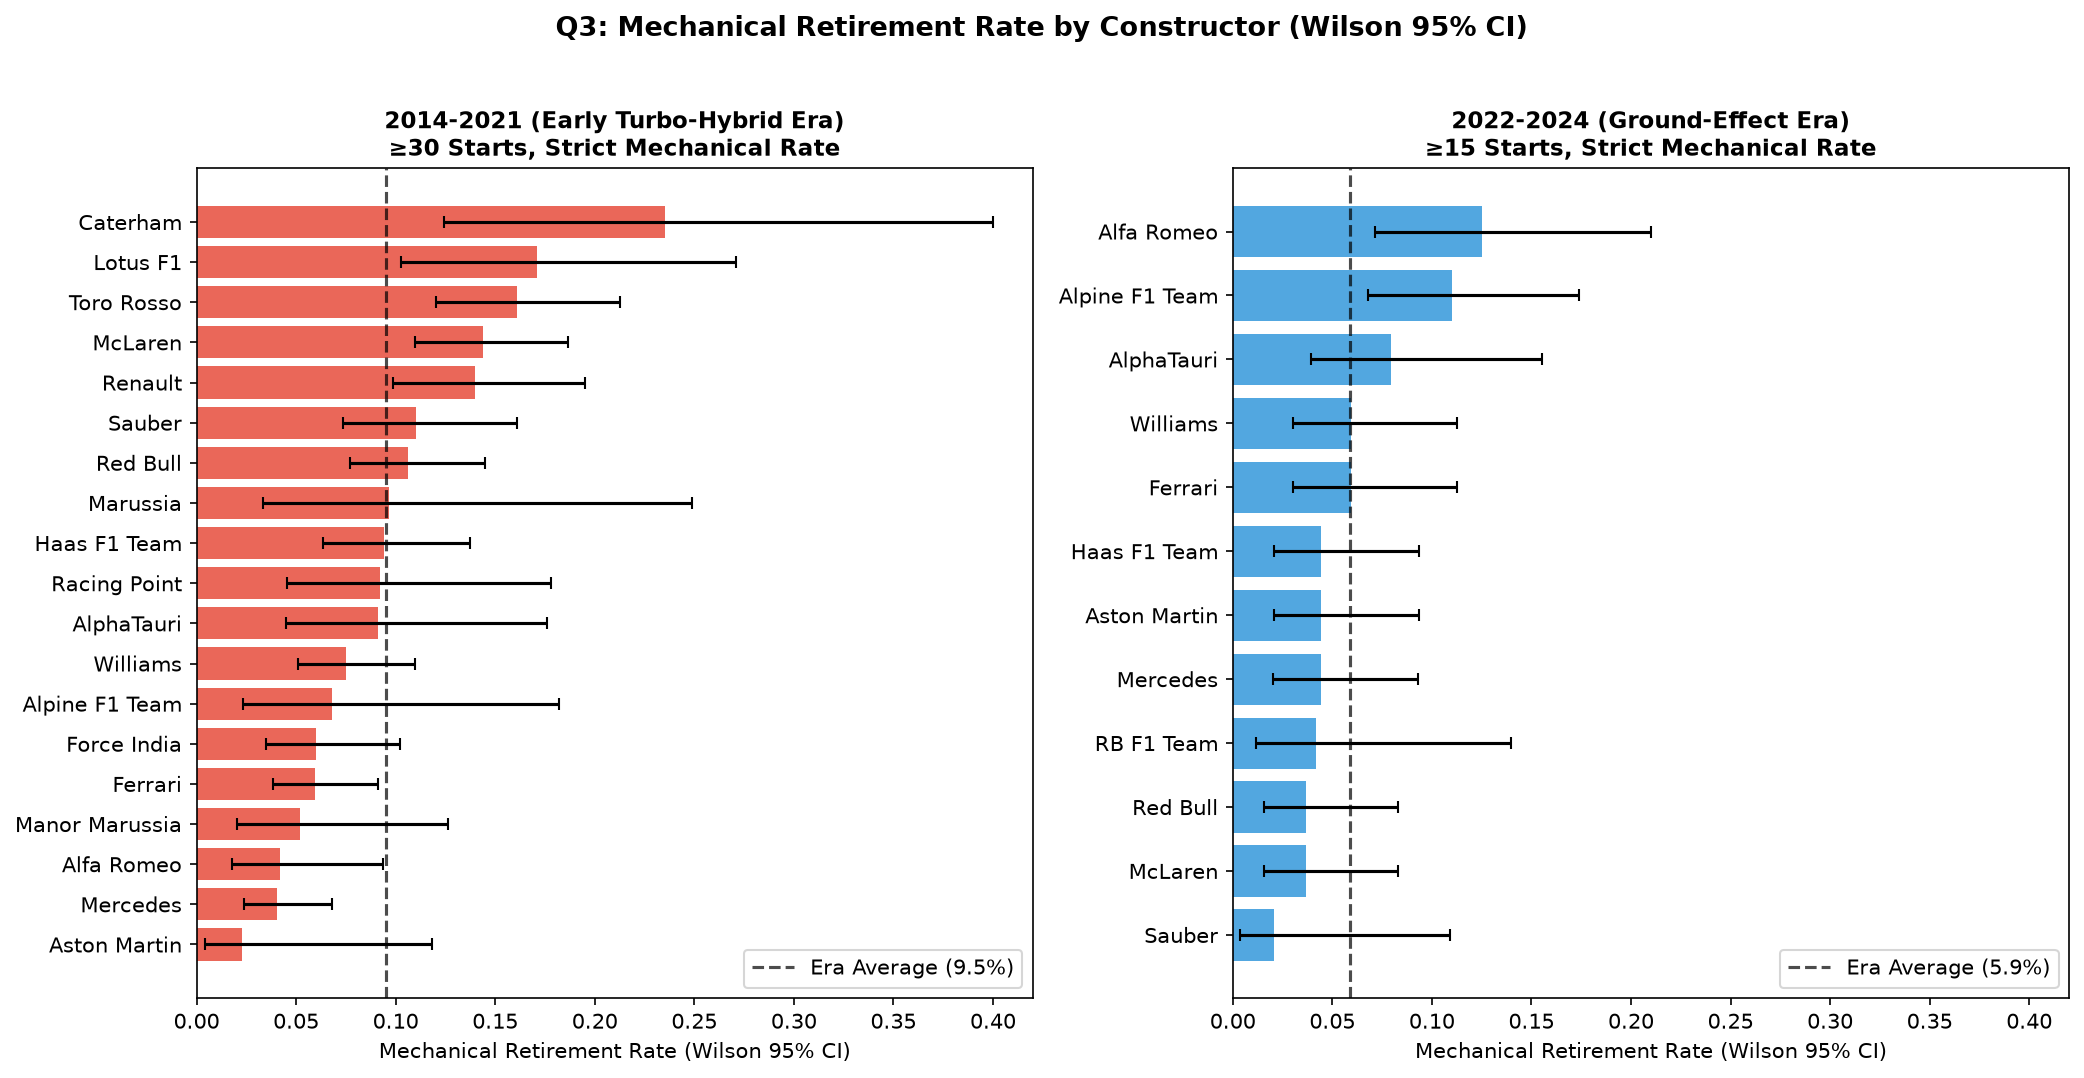

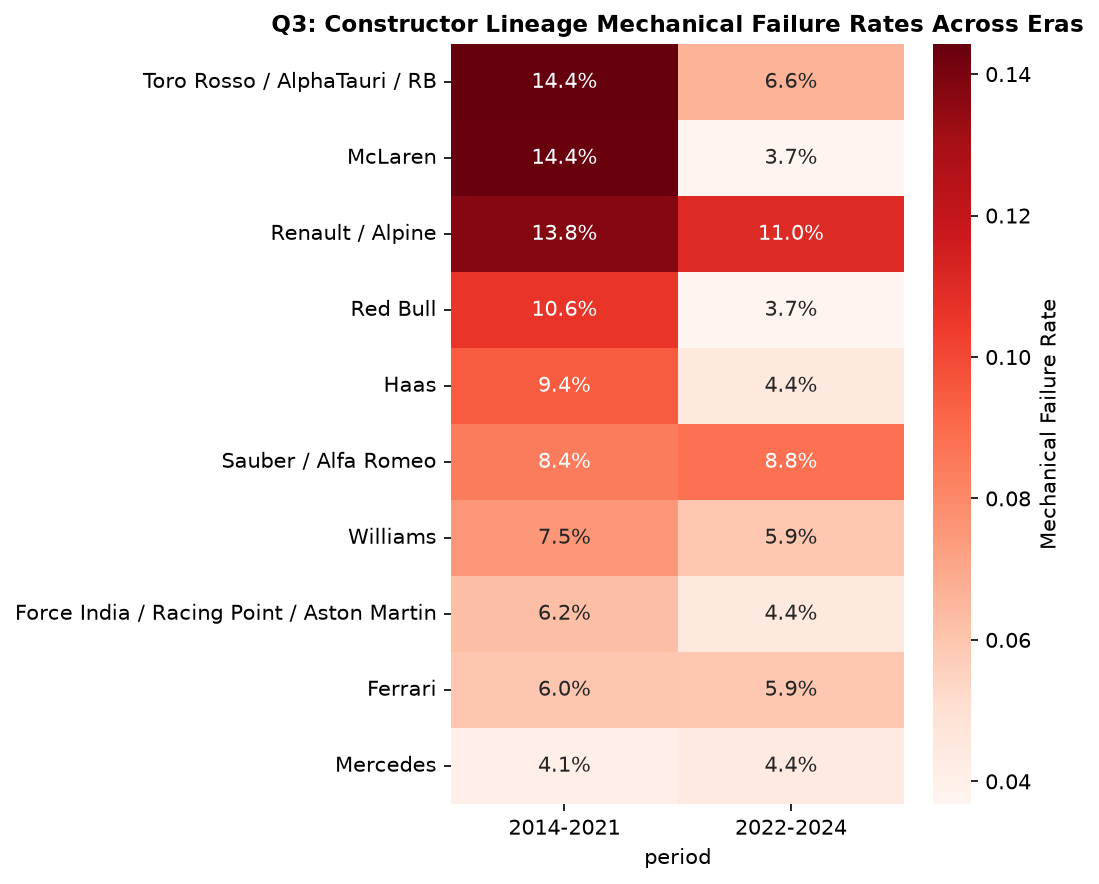

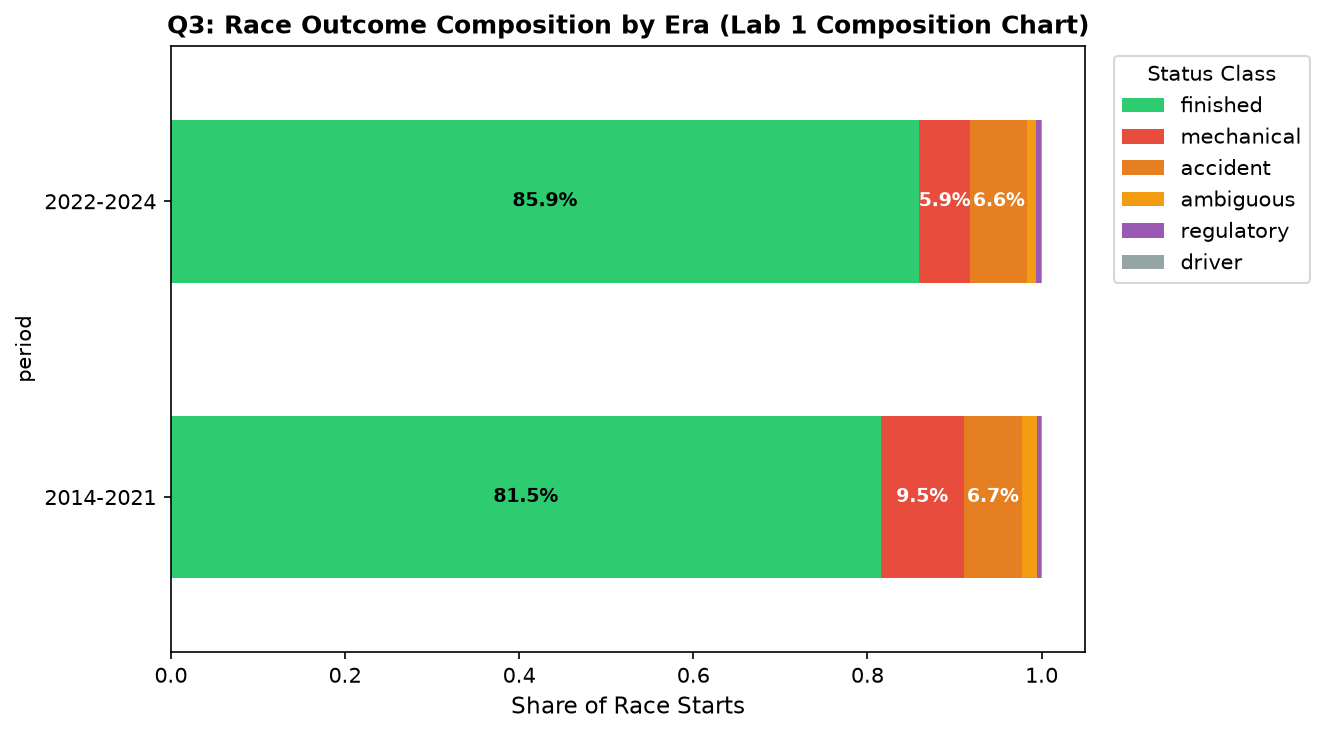

Top mechanical failure rates 2014-2021:


,starts,failures,rate
constructor_name,,,
Caterham,34,8,0.235294
Lotus F1,76,13,0.171053
Toro Rosso,242,39,0.161157
McLaren,320,46,0.143750
Renault,200,28,0.140000
Sauber,200,22,0.110000


Top mechanical failure rates 2022-2024:


,starts,failures,rate
constructor_name,,,
Alfa Romeo,88,11,0.125000
Alpine F1 Team,136,15,0.110294
AlphaTauri,88,7,0.079545
Ferrari,135,8,0.059259
Williams,135,8,0.059259
Aston Martin,135,6,0.044444


In [ ]:
# Primary analysis by constructorId (>=30 starts both windows: same constructors either way).
era_avg_p1 = float(overall_q3.loc["2014-2021", "strict_rate"])
era_avg_p2 = float(overall_q3.loc["2022-2024", "strict_rate"])
p1_sub = q3_starts[q3_starts["period"] == "2014-2021"].groupby("constructor_name")["mech_strict"].agg(["sum", "count"])
p1_sub = p1_sub[p1_sub["count"] >= 30]
r1, l1, h1 = wilson_interval(p1_sub["sum"], p1_sub["count"])
p1_sub["rate"] = r1; p1_sub["err_l"] = r1 - l1; p1_sub["err_h"] = h1 - r1

p2_sub = q3_starts[q3_starts["period"] == "2022-2024"].groupby("constructor_name")["mech_strict"].agg(["sum", "count"])
p2_sub = p2_sub[p2_sub["count"] >= 30]
r2, l2, h2 = wilson_interval(p2_sub["sum"], p2_sub["count"])
p2_sub["rate"] = r2; p2_sub["err_l"] = r2 - l2; p2_sub["err_h"] = h2 - r2

# Plot fig_13: Horizontal barplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), sharex=True)

p1_sorted = p1_sub.sort_values("rate", ascending=True)
ax1.barh(p1_sorted.index, p1_sorted["rate"], color="#e74c3c", alpha=0.85,
         xerr=[p1_sorted["err_l"], p1_sorted["err_h"]], capsize=3)
ax1.set_title("2014-2021 (Early Turbo-Hybrid Era)\n≥30 Starts, Strict Mechanical Rate", fontsize=11, fontweight="bold")
ax1.set_xlabel("Mechanical Retirement Rate (Wilson 95% CI)", fontsize=10)
ax1.axvline(era_avg_p1, color="black", linestyle="--", alpha=0.7, label=f"Era Average ({era_avg_p1:.1%})")
ax1.legend(loc="lower right")

p2_sorted = p2_sub.sort_values("rate", ascending=True)
ax2.barh(p2_sorted.index, p2_sorted["rate"], color="#3498db", alpha=0.85,
         xerr=[p2_sorted["err_l"], p2_sorted["err_h"]], capsize=3)
ax2.set_title("2022-2024 (Ground-Effect Era)\n≥30 Starts, Strict Mechanical Rate", fontsize=11, fontweight="bold")
ax2.set_xlabel("Mechanical Retirement Rate (Wilson 95% CI)", fontsize=10)
ax2.axvline(era_avg_p2, color="black", linestyle="--", alpha=0.7, label=f"Era Average ({era_avg_p2:.1%})")
ax2.legend(loc="lower right")

plt.suptitle("Q3: Mechanical Retirement Rate by Constructor (Wilson 95% CI)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_13_q3_constructor_bars.png", dpi=150, bbox_inches="tight")
plt.show()

# Plot fig_14: Lineage Heatmap
lineage_grp = q3_starts.groupby(["lineage", "period"])["mech_strict"].agg(["sum", "count"]).reset_index()
r_lin, _, _ = wilson_interval(lineage_grp["sum"], lineage_grp["count"])
lineage_grp["rate"] = r_lin
piv_lin = lineage_grp.pivot(index="lineage", columns="period", values="rate").dropna()
piv_lin = piv_lin.sort_values("2014-2021", ascending=False)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(piv_lin, annot=True, fmt=".1%", cmap="Reds", ax=ax, cbar_kws={"label": "Mechanical Failure Rate"})
ax.set_title("Q3: Constructor Lineage Mechanical Failure Rates Across Eras", fontsize=11, fontweight="bold")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_14_q3_heatmap_pivot.png", dpi=150)
plt.show()

# Plot fig_15: Retirement composition stacked bar chart (Lab 1 composition pattern)
comp = q3_starts.groupby(["period", "status_class"]).size().unstack(fill_value=0)
comp_pct = comp.div(comp.sum(axis=1), axis=0)[["finished", "mechanical", "accident", "ambiguous", "regulatory", "driver"]]

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2ecc71", "#e74c3c", "#e67e22", "#f39c12", "#9b59b6", "#95a5a6"]
comp_pct.plot(kind="barh", stacked=True, color=colors, ax=ax, width=0.55)
ax.set_xlabel("Share of Race Starts", fontsize=11)
ax.set_title("Q3: Race Outcome Composition by Era (Lab 1 Composition Chart)", fontsize=12, fontweight="bold")
ax.legend(title="Status Class", bbox_to_anchor=(1.02, 1), loc="upper left")
for n, c in enumerate(comp_pct.columns):
    for i, val in enumerate(comp_pct[c]):
        if val > 0.03:
            cum_val = comp_pct.iloc[i, :n].sum() + val / 2
            ax.text(cum_val, i, f"{val:.1%}", ha="center", va="center", color="white" if c in ["mechanical", "accident"] else "black", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_15_q3_retirement_composition.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top mechanical failure rates 2014-2021:")
display(p1_sorted.sort_values("rate", ascending=False)[["count", "sum", "rate"]].rename(columns={"count": "starts", "sum": "failures"}).head(6))
print("Top mechanical failure rates 2022-2024:")
display(p2_sorted.sort_values("rate", ascending=False)[["count", "sum", "rate"]].rename(columns={"count": "starts", "sum": "failures"}).head(6))

**Answer:** 9.5% (2014–21) → 5.9% (2022–24); worst P1 Caterham 23.5%, P2 Alfa Romeo 12.5%; strict/broad rankings stable (ρ>0.95). Details: `docs/phase3.md`.


In [ ]:
# Update Decision Log with Phase 3 Gates
DECISIONS.extend([
    (13, "Gate Q1.A: Dual front-row view (Grid all-history vs Quali 2003+)", "decided",
     "2026-10-03: qualifying sparse pre-2003; Grid FR covers 1950-2024, Quali FR covers complete modern era. Both reported."),
    (14, "Gate Q1.B: Small-sample threshold k=10 front-row starts", "decided",
     "2026-10-03: 16 circuits meet k>=10 in both eras; small samples excluded from rankings to avoid noise and reported separately."),
    (15, "Gate Q2.A: Indy 500 exclusion & dual-method agreement on home effect", "decided",
     "2026-10-03: Indy 500 excluded from primary Q2 view (oval, US-only). Stratified (-0.70% gap) and Logistic Regression (OR 0.915, CI [0.785, 1.082]) agree: no home advantage."),
    (16, "Gate Q3.A: Strict mechanical taxonomy confirmed primary", "decided",
     "2026-10-03: strict mechanical excludes crashes/regulations; broad sensitivity check confirms rankings are highly stable (Spearman rho > 0.95)."),
])

decisions = pd.DataFrame(DECISIONS, columns=["#", "decision", "status", "rationale / where"])
display(decisions.tail(6))
print(f"Total Decisions Logged: {len(decisions)} (all decided, 0 open)")

,#,decision,status,rationale / where
10,11,PR-AUC primary; ROC-AUC + F1@val-threshold secondary,decided,"decided 2026-10-03: base rate 12.7% overall, ~15% modern era -> PR-AUC primary; +Precision/Recall (the brief's five); Accuracy reference-only (Lab 2: ~87% no-skill, misleading on imbalance)"
11,12,"Phase 2 cleaning on copies (types, R2, flags, taxonomy)",decided,"2026-10-03, section 12: durations unit-checked (ms/1000), PK/FK 0 orphans, 72 pit-lane kept / 1,566 non-starters out, Indy flagged, strict status taxonomy; impact table + before/after figs"
12,13,Gate Q1.A: Dual front-row view (Grid all-history vs Quali 2003+),decided,"2026-10-03: qualifying sparse pre-2003; Grid FR covers 1950-2024, Quali FR covers complete modern era. Both reported."
13,14,Gate Q1.B: Small-sample threshold k=10 front-row starts,decided,2026-10-03: 16 circuits meet k>=10 in both eras; small samples excluded from rankings to avoid noise and reported separately.
14,15,Gate Q2.A: Indy 500 exclusion & dual-method agreement on home effect,decided,"2026-10-03: Indy 500 excluded from primary Q2 view (oval, US-only). Stratified (-0.70% gap) and Logistic Regression (OR 0.915, CI [0.785, 1.082]) agree: no home advantage."
15,16,Gate Q3.A: Strict mechanical taxonomy confirmed primary,decided,2026-10-03: strict mechanical excludes crashes/regulations; broad sensitivity check confirms rankings are highly stable (Spearman rho > 0.95).


Total Decisions Logged: 16 (all decided, 0 open)


§15. Roadmap

§§2–14 done; features, splits, models, XAI, inference, report per `PLAN.md`.


In [135]:
# Guard (stays last): raw CSVs byte-identical to load time
import hashlib
for t in TABLES:
    h = hashlib.sha256()
    with open(RAW_DIR / f"{t}.csv", "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    assert h.hexdigest() == RAW_CHECKSUMS[t], f"raw {t}.csv changed since load!"
print("raw integrity OK: all 14 checksums match (Gate: raw files never modified)")


raw integrity OK: all 14 checksums match (Gate: raw files never modified)
